# Phase II · 01 · Inside the baseline CNN

Phase I (`phase1/`) showed *what* the CNN does: blur and resizing push fakes toward REAL, sharpening pushes real photos toward FAKE, and many images move together. This notebook opens the model to ask *how* it gets there, using the techniques from the lectures on visual explanations:

| View | Lecture technique | What it shows |
| --- | --- | --- |
| Grad-CAM (5.1) | Gradient-based attribution | Coarse regions with positive support for FAKE |
| Neuron contributions (5.2) | Exact linear decomposition | How 64 activations × weights + bias give the logit |
| Occlusion (5.3) | Perturbation-based attribution | Score change when a 4×4 patch is covered |
| Filters and arithmetic (6.1–6.2) | Weight visualization | The learned 3×3 RGB kernels and one convolution step |
| Feature maps and top patches (6.3–6.4) | Activation maps, dataset examples | Where a channel responds and what activates it most |
| Channel removal (6.5) | Ablation | Which channels help or hurt under clean, resized and JPEG inputs |

All calculations use the frozen baseline and the validation images bundled in this notebook; no dataset download or training is needed. The cells are Sections 12–13 of `baseline_training.ipynb`, moved here with new section numbers. Section 4 holds the hidden modification code and saved Phase I probe that the image pairs are built from.

## 1. Environment and notebook implementation

Use Python 3.12 and select that environment as the notebook kernel in VS Code or Jupyter. If dependencies are missing, set `INSTALL_DEPENDENCIES = True` in the next cell, run it once, restart the kernel if prompted, then set it back to `False`. This installs packages in the current kernel environment; the default Run All does not install or download anything.

The helper cells below contain the entire implementation. The collapsed **bundled baseline** cell carries the selected trained weights, numerical results, and static figures, so copying this `.ipynb` is enough to share the baseline. You can leave that cell collapsed.

In [1]:
INSTALL_DEPENDENCIES = False
PACKAGES = [
    "kagglehub==1.0.3",
    "torch==2.15.0",
    "numpy==2.5.4",
    "pillow==13.0.0",
    "scikit-learn==1.9.1",
    "matplotlib==3.11.2",
    "jupyterlab==4.6.5",
    "ipykernel==7.4.0",
    "nbformat==5.11.1",
    "nbclient==0.11.0",
    "plotly==7.1.0",
    "anywidget==0.11.0",
    "ipywidgets==8.1.9",
]

if INSTALL_DEPENDENCIES:
    get_ipython().run_line_magic("pip", "install " + " ".join(PACKAGES))
else:
    print("Using the current kernel environment; installation is disabled.")


Using the current kernel environment; installation is disabled.


In [2]:
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
from io import BytesIO, StringIO
from types import SimpleNamespace
import base64
import csv
import hashlib
import importlib.metadata
import json
import logging
import os
import platform
import random
import shutil
import sys
import tarfile
import tempfile
import time

NOTEBOOK_PATH = Path.cwd().resolve() / "01_cnn_internals.ipynb"
# Phase notebooks sit one folder below the repository root; data, runs and results stay at the root.
ROOT = next(
    (p for p in (NOTEBOOK_PATH.parent, *NOTEBOOK_PATH.parents) if (p / "team-info.json").exists()),
    NOTEBOOK_PATH.parent,
)
os.environ.setdefault(
    "MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "cifake-matplotlib")
)

import numpy as np
import torch
from torch import nn
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, roc_auc_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

get_ipython().run_line_magic("matplotlib", "inline")
torch.set_num_threads(4)


def read_json(path):
    return json.loads(Path(path).read_text())


def read_csv(path):
    with Path(path).open(newline="") as handle:
        return list(csv.DictReader(handle))


def show_table(headers, rows):
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]
    lines += ["| " + " | ".join(str(value) for value in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def snapshot_notebook(source_dir):
    """Record the notebook and the code actually executed for a new training run."""
    if not NOTEBOOK_PATH.is_file():
        raise FileNotFoundError(
            "Save this notebook and set NOTEBOOK_PATH to its filename before training."
        )
    shutil.copy2(NOTEBOOK_PATH, source_dir / "baseline_training.ipynb")
    shell = get_ipython()
    if shell is not None:
        inputs = [
            s
            for s in shell.history_manager.input_hist_raw
            if s and "EMBEDDED_ASSETS =" not in s
        ]
        (source_dir / "executed_cells.txt").write_text(
            "\n\n# --- next executed cell ---\n\n".join(inputs)
        )


print(f"Python {sys.version.split()[0]} · PyTorch {torch.__version__}")
print("Working directory:", ROOT)


### Bundled baseline and reusable notebook functions

Run the following cells once. They define the helpers without starting training; the bundled baseline cell can stay collapsed.

**Saved review data.** The trained weights and saved measurements are stored in notebook metadata, so there is no long encoded string to scroll through. This short loader checks and decodes the data when needed. Keep the complete `.ipynb` file when sharing it.

In [3]:
# These assets travel inside the .ipynb, outside the visible code cells.
# They include the trained CNN, saved metrics and the figures used in review mode.
_NOTEBOOK_PAYLOADS = None


def notebook_payload(name):
    """Read the saved notebook once and retrieve one embedded data block."""
    global _NOTEBOOK_PAYLOADS
    if _NOTEBOOK_PAYLOADS is None:
        if not NOTEBOOK_PATH.is_file():
            raise FileNotFoundError(
                "Save this notebook and set NOTEBOOK_PATH to its filename before review."
            )
        saved_notebook = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
        _NOTEBOOK_PAYLOADS = saved_notebook["metadata"]["cifake"]
    return _NOTEBOOK_PAYLOADS[name]


# Bundled selected model and saved results. Leave this cell collapsed.
EMBEDDED_RUN = "baseline_plain_seed1"
EMBEDDED_ASSETS = notebook_payload("baseline_assets")


def embedded_bytes(name):
    """Decode one bundled asset and check its checksum before using it."""
    item = EMBEDDED_ASSETS.get(name)
    if item is None:
        return None
    raw = base64.b64decode(item["base64"], validate=True)
    if hashlib.sha256(raw).hexdigest() != item["sha256"]:
        raise ValueError(f"Bundled artifact integrity check failed: {name}")
    return raw


for artifact_name in EMBEDDED_ASSETS:
    embedded_bytes(artifact_name)
print(
    "Bundled baseline verified: trained weights, metrics, history, and static figures are available in memory."
)


Bundled baseline verified: trained weights, metrics, history, and static figures are available in memory.


**The baseline architecture.** The model is a small CNN with two convolution-and-pooling stages and a 64-unit hidden layer. Its output is a REAL logit; converting it to a probability and applying the fixed threshold happens in the evaluation helpers.

In [4]:
LABELS = {"FAKE": 0, "REAL": 1}  # Matches the paper; sigmoid(logit) = P(REAL).


class BaselineCNN(nn.Module):
    """Paper-inspired 32/32 convolutional filters and one 64-unit dense layer.

    3x3 valid convolutions, ReLU, 2x2 max pooling after each convolution.
    32x32 -> 30x30 -> 15x15 -> 13x13 -> 6x6 -> 1152 -> 64 -> 1.
    No augmentation, dropout, batch normalization, or pretrained weights.
    """

    def __init__(self):
        super().__init__()
        # Learn local patterns, then reduce their spatial size with max pooling.
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 32, 3),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        # Combine the 32 feature maps into 64 hidden values and one REAL logit.
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(1152, 64), nn.ReLU(), nn.Linear(64, 1)
        )
        # Initialize this small network from scratch; no pretrained weights are used.
        for layer in self.modules():
            if isinstance(layer, (nn.Conv2d, nn.Linear)):
                nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)


**Data integrity and predictions.** These helpers check the data, prepare batches and calculate metrics. File checksums keep the split consistent when the notebook is shared.

In [5]:
def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def write_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")
    temporary.replace(path)


def choose_device(name="auto"):
    if name == "auto":
        name = (
            "cuda"
            if torch.cuda.is_available()
            else "mps" if torch.backends.mps.is_available() else "cpu"
        )
    if name == "mps" and not torch.backends.mps.is_available():
        raise RuntimeError(
            "MPS is unavailable in this process. Use an allowed GPU process or --device cpu."
        )
    return torch.device(name)


def verify_run_data(data_dir, run_dir, config):
    """Compare content, not machine-specific absolute paths, for team portability."""
    data_dir, run_dir = Path(data_dir), Path(run_dir)
    expected = json.loads((run_dir / "data_audit.json").read_text())
    actual = json.loads((data_dir / "audit.json").read_text())
    if (
        file_sha256(data_dir / "manifest.csv") != config["manifest_sha256"]
        or actual["file_sha256"] != expected["file_sha256"]
    ):
        raise ValueError("Prepared dataset differs from the data used in this run")


def load_split(data_dir, split):
    """Verify cached data against the audit before using it."""
    data_dir = Path(data_dir)
    audit = json.loads((data_dir / "audit.json").read_text())
    for filename in ("manifest.csv", f"{split}_images.npy", f"{split}_labels.npy"):
        if file_sha256(data_dir / filename) != audit["file_sha256"][filename]:
            raise ValueError(f"Prepared file changed after audit: {filename}")
    images = np.load(data_dir / f"{split}_images.npy", allow_pickle=False)
    labels = np.load(data_dir / f"{split}_labels.npy", allow_pickle=False)
    with (data_dir / "manifest.csv").open(newline="") as handle:
        rows = [row for row in csv.DictReader(handle) if row["split"] == split]
    if images.dtype != np.uint8 or images.shape != (len(rows), 3, 32, 32):
        raise ValueError(f"Invalid image cache for {split}")
    if not np.array_equal(labels, [int(row["label"]) for row in rows]):
        raise ValueError(f"Labels do not match manifest for {split}")
    return images, labels, rows


def batches(images, labels, batch_size, device, order=None):
    if order is None:
        order = np.arange(len(labels))
    for offset in range(0, len(order), batch_size):
        idx = order[offset : offset + batch_size]
        x = (
            torch.from_numpy(images[idx])
            .to(device=device, dtype=torch.float32)
            .div_(255)
        )
        y = torch.from_numpy(labels[idx]).to(device=device, dtype=torch.float32)
        yield x, y


@torch.inference_mode()
def predict(model, images, labels, batch_size, device):
    """Run evaluation batches without updating the weights or tracking gradients."""
    model.eval()
    logits = [
        model(x).cpu().numpy() for x, _ in batches(images, labels, batch_size, device)
    ]
    return np.concatenate(logits)


def classification_metrics(labels, logits):
    """Summarize predictions with FAKE=0, REAL=1 and a fixed 0.5 threshold."""
    logits = np.asarray(logits, dtype=np.float64)
    labels = np.asarray(labels, dtype=np.int64)
    if len(labels) != len(logits) or not np.isfinite(logits).all():
        raise ValueError("Invalid predictions")
    predicted = (logits >= 0).astype(np.int64)
    cm = confusion_matrix(labels, predicted, labels=[0, 1])
    # Stable BCE and sigmoid. Threshold is fixed in advance at P(REAL) >= 0.5.
    p_real = np.exp(-np.logaddexp(0, -logits))
    return {
        "n": len(labels),
        "loss": float(np.mean(np.logaddexp(0, logits) - labels * logits)),
        "accuracy": float(accuracy_score(labels, predicted)),
        "balanced_accuracy": float(np.mean(np.diag(cm) / cm.sum(axis=1))),
        "f1_fake": float(f1_score(labels, predicted, pos_label=0)),
        "roc_auc_fake": float(roc_auc_score(labels == 0, -logits)),
        "fake_detection_rate": float(cm[0, 0] / cm[0].sum()),
        "real_flagged_fake_rate": float(cm[1, 0] / cm[1].sum()),
        "brier_score_fake": float(np.mean(((1 - p_real) - (labels == 0)) ** 2)),
        "confusion_matrix": cm.tolist(),
        "confusion_matrix_order": ["FAKE", "REAL"],
        "confusion_matrix_axes": "rows=true, columns=predicted",
        "decision_rule": "REAL if sigmoid(logit) >= 0.5, otherwise FAKE",
    }


def save_predictions(path, rows, logits):
    p_real = np.exp(-np.logaddexp(0, -np.asarray(logits, dtype=np.float64)))
    with Path(path).open("w", newline="") as handle:
        writer = csv.writer(handle)
        writer.writerow(
            [
                "path",
                "pixel_sha256",
                "label",
                "class_name",
                "logit_real",
                "p_real",
                "p_fake",
                "prediction",
                "correct",
            ]
        )
        for row, logit, probability in zip(rows, logits, p_real, strict=True):
            prediction = "REAL" if logit >= 0 else "FAKE"
            writer.writerow(
                [
                    row["path"],
                    row["pixel_sha256"],
                    row["label"],
                    row["class_name"],
                    float(logit),
                    float(probability),
                    float(1 - probability),
                    prediction,
                    prediction == row["class_name"],
                ]
            )


In [6]:
def assign_splits(records, validation_per_class=5000, seed=1):
    """Keep the official test set. Deduplicate development data before sampling."""
    labels_by_hash = defaultdict(set)
    for row in records:
        labels_by_hash[row["pixel_sha256"]].add(row["label"])
    if any(len(labels) != 1 for labels in labels_by_hash.values()):
        raise ValueError(
            "Identical pixels have conflicting labels; resolve before training."
        )
    test_hashes = {r["pixel_sha256"] for r in records if r["source_split"] == "test"}
    seen = set()
    for row in records:
        row["exclusion_reason"] = ""
        if row["source_split"] == "test":
            row["split"] = "test"
        elif row["pixel_sha256"] in test_hashes:
            row["split"], row["exclusion_reason"] = (
                "excluded",
                "identical_to_official_test",
            )
        elif row["pixel_sha256"] in seen:
            row["split"], row["exclusion_reason"] = (
                "excluded",
                "repeated_training_image",
            )
        else:
            row["split"] = "train"
            seen.add(row["pixel_sha256"])
    rng = np.random.default_rng(seed)
    for label in LABELS.values():
        eligible = [
            i
            for i, r in enumerate(records)
            if r["split"] == "train" and r["label"] == label
        ]
        if len(eligible) <= validation_per_class:
            raise ValueError(
                "Not enough unique images for the requested validation size"
            )
        for idx in rng.permutation(eligible)[:validation_per_class]:
            records[idx]["split"] = "val"
    hashes = {
        s: {r["pixel_sha256"] for r in records if r["split"] == s}
        for s in ("train", "val", "test")
    }
    if (
        hashes["train"] & hashes["val"]
        or hashes["train"] & hashes["test"]
        or hashes["val"] & hashes["test"]
    ):
        raise AssertionError("Pixel overlap across splits")
    return records


def prepare_data(data_root, output, seed=1, validation_per_class=5000):
    """Audit the images, assign the fixed splits and save arrays for training."""
    args = SimpleNamespace(
        data_root=Path(data_root),
        output=Path(output),
        seed=seed,
        validation_per_class=validation_per_class,
    )
    if args.output.exists():
        raise SystemExit(
            f"Refusing to overwrite {args.output}; reuse it or choose a new --output."
        )
    if args.validation_per_class < 1:
        raise SystemExit("Validation size must be positive")

    records, images = [], []
    for source in ("train", "test"):
        for class_name, label in LABELS.items():
            paths = sorted((args.data_root / source / class_name).glob("*.jpg"))
            expected = 50000 if source == "train" else 10000
            if len(paths) != expected:
                raise ValueError(
                    f"{source}/{class_name}: expected {expected}, found {len(paths)}"
                )
            for path in paths:
                with Image.open(path) as im:
                    if im.size != (32, 32) or im.mode != "RGB":
                        raise ValueError(f"Expected 32x32 RGB: {path}")
                    pixels = np.array(im, dtype=np.uint8)
                images.append(pixels.transpose(2, 0, 1))
                records.append(
                    {
                        "path": path.relative_to(args.data_root).as_posix(),
                        "source_split": source,
                        "class_name": class_name,
                        "label": label,
                        "pixel_sha256": hashlib.sha256(pixels.tobytes()).hexdigest(),
                    }
                )
            print(
                f"Decoded and hashed {source}/{class_name}: {len(paths):,}", flush=True
            )
    assign_splits(records, args.validation_per_class, args.seed)
    args.output.mkdir(parents=True)
    fields = [
        "path",
        "source_split",
        "class_name",
        "label",
        "pixel_sha256",
        "split",
        "exclusion_reason",
    ]
    with (args.output / "manifest.csv").open("w", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=fields)
        writer.writeheader()
        writer.writerows(records)
    for split in ("train", "val", "test"):
        indices = [i for i, r in enumerate(records) if r["split"] == split]
        np.save(
            args.output / f"{split}_images.npy", np.stack([images[i] for i in indices])
        )
        np.save(
            args.output / f"{split}_labels.npy",
            np.array([records[i]["label"] for i in indices], dtype=np.int64),
        )
    counts = {
        s: dict(Counter(r["class_name"] for r in records if r["split"] == s))
        for s in ("train", "val", "test", "excluded")
    }
    test_hashes = [r["pixel_sha256"] for r in records if r["split"] == "test"]
    all_hashes = Counter(r["pixel_sha256"] for r in records)
    audit = {
        "seed": args.seed,
        "validation_per_class": args.validation_per_class,
        "source_root": str(args.data_root.resolve()),
        "class_to_index": LABELS,
        "split_counts": counts,
        "exclusion_counts": dict(
            Counter(r["exclusion_reason"] for r in records if r["split"] == "excluded")
        ),
        "duplicate_groups_in_original_data": sum(v > 1 for v in all_hashes.values()),
        "official_test_size": len(test_hashes),
        "unique_test_images": len(set(test_hashes)),
        "exact_pixel_overlap_across_splits": 0,
        "policy": "Preserve official test; exclude training copies of test images; retain one copy of each remaining training image; seeded balanced validation holdout.",
        "limitations": "Exact decoded RGB duplicates only; near-duplicates are not detected. Stratified by REAL/FAKE, not unverified semantic classes.",
        "preprocessing": "Decode RGB at native 32x32; float32 / 255 at batch time; no augmentation.",
        "file_sha256": {
            p.name: file_sha256(p) for p in sorted(args.output.iterdir()) if p.is_file()
        },
    }
    write_json(args.output / "audit.json", audit)
    print(f"Split counts: {counts}", flush=True)
    print(
        f"Exclusions: {audit['exclusion_counts']}; unique test images: {len(set(test_hashes)):,}",
        flush=True,
    )
    print(f"Prepared data: {args.output}", flush=True)


## 2. Configuration

This notebook only **reviews** the saved baseline. Training, resuming and the official test evaluation live in `baseline_training.ipynb`. `SPLIT_SEED` and `RUN_NAME` must match the run whose weights are bundled here.

In [7]:
# Keep review mode to inspect the saved experiment. Use a new run name for a new training experiment.
MODE = "review"  # Fixed: train in baseline_training.ipynb.
RUN_NAME = "baseline_plain_seed1"  # Use a NEW name to train another model.
DEVICE = "auto"  # "auto", "mps", "cuda", or "cpu"

RUN_BEHAVIOR_PROBE = False  # Recompute the frozen-model validation sweep.
RUN_INTERNAL_PROBE = False  # Recompute the sampled validation filter investigation.
SAVE_FIGURES = False  # Optional local PNG/summary copies.
DOWNLOAD_DATA = False
PREPARE_DATA = False

SPLIT_SEED = 1
VALIDATION_PER_CLASS = 5000
TRAINING = {
    "seed": 1,
    "epochs": 30,
    "batch_size": 128,
    "learning_rate": 0.001,
    "patience": 5,
    "min_delta": 0.0001,
}

assert MODE in {"review", "train", "resume"}
assert RUN_NAME and Path(RUN_NAME).name == RUN_NAME and RUN_NAME not in {".", ".."}
RAW_DATA = ROOT / "data" / "cifake"
DATA_DIR = ROOT / "data" / f"baseline_seed{SPLIT_SEED}"
RUN_DIR = ROOT / "runs" / RUN_NAME
RESULTS_DIR = ROOT / "results" / RUN_NAME
MODEL_PATH = ROOT / "models" / f"{RUN_NAME}.pt"
device = choose_device(DEVICE)


def result_bytes(name):
    for directory in (RUN_DIR, RESULTS_DIR):
        path = directory / name
        if path.exists():
            return path.read_bytes()
    if RUN_NAME == EMBEDDED_RUN and SPLIT_SEED == 1:
        return embedded_bytes(f"results/{EMBEDDED_RUN}/{name}")
    return None


def read_result(name):
    raw = result_bytes(name)
    if raw is None:
        return None
    if name.endswith(".csv"):
        return list(csv.DictReader(StringIO(raw.decode("utf-8"))))
    return json.loads(raw)


show_table(
    ["Setting", "Value"],
    [
        ("Mode", MODE),
        ("Run", RUN_NAME),
        ("Device", str(device)),
        ("Augmentation", "None"),
        *TRAINING.items(),
    ],
)

| Setting | Value |
| --- | --- |
| Mode | review |
| Run | baseline_plain_seed1 |
| Device | mps |
| Augmentation | None |
| seed | 1 |
| epochs | 30 |
| batch_size | 128 |
| learning_rate | 0.001 |
| patience | 5 |
| min_delta | 0.0001 |

## 3. Load the selected model for analysis

For the completed baseline, the trained weights are included **inside this notebook** and can be loaded on a CPU. No retraining, dataset download, sibling `.py` file, or separate model file is required. If a local full run is present, its selected `best.pt` is used. New named runs use their own selected checkpoints; they never silently fall back to the bundled baseline.

The loaded `model` is ready for later analysis. Inputs must be `[batch, 3, 32, 32]` RGB float tensors scaled to `[0,1]` on `device`. `torch.sigmoid(model(inputs))` gives P(REAL). Full optimizer and recovery states stay in local training checkpoints; the bundled weights are for inference.

In [8]:
# This notebook does not train. The selected epoch comes from the saved training summary.
run_summary = read_result("summary.json")
selected_epoch = run_summary.get("best_epoch", run_summary.get("selected_epoch")) if run_summary else None
if run_summary:
    print(f"Selected epoch: {selected_epoch} · validation accuracy {run_summary['validation']['accuracy']:.2%}")

Selected epoch: 19 · validation accuracy 94.54%


In [9]:
# Load the selected checkpoint, falling back to the trained weights stored inside this notebook.
checkpoint = None
model = None
checkpoint_path = RUN_DIR / "best.pt"
if checkpoint_path.exists():
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    checkpoint_source = checkpoint_path.relative_to(ROOT).as_posix()
elif MODEL_PATH.exists():
    exported_summary = read_json(RESULTS_DIR / "summary.json")
    assert file_sha256(MODEL_PATH) == exported_summary["model_sha256"]
    checkpoint = torch.load(MODEL_PATH, map_location="cpu", weights_only=True)
    checkpoint_source = MODEL_PATH.relative_to(ROOT).as_posix()
elif RUN_NAME == EMBEDDED_RUN and SPLIT_SEED == 1:
    raw_weights = embedded_bytes(f"models/{EMBEDDED_RUN}.pt")
    assert (
        hashlib.sha256(raw_weights).hexdigest()
        == read_result("summary.json")["model_sha256"]
    )
    checkpoint = torch.load(BytesIO(raw_weights), map_location="cpu", weights_only=True)
    checkpoint_source = "the weights bundled inside this notebook"

if checkpoint is not None:
    model = BaselineCNN().to(device)
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    model.eval()
    assert checkpoint["epoch"] == selected_epoch
    print(f"Loaded epoch {checkpoint['epoch']} from {checkpoint_source}")
    print("Output convention: p_real = sigmoid(logit); p_fake = 1 - p_real.")
else:
    print("No selected checkpoint exists for this named run. Finish training first.")


Loaded epoch 19 from the weights bundled inside this notebook
Output convention: p_real = sigmoid(logit); p_fake = 1 - p_real.


## 4. The modification probe from Phase I

The image pairs below compare an original validation image with an edited version of itself. These hidden cells define the same JPEG, blur, resize and noise edits as `phase1/02_cnn_behaviour.ipynb` and load its saved 10,000-image probe, which supplies the example images and their scores. The behaviour figures themselves are in that notebook.

**Defining the image changes.** We use named, fixed strengths of JPEG compression, blur, resizing and noise. Each modification is applied at the original image resolution so the input change can be inspected directly.

In [10]:
from io import BytesIO
from PIL import Image, ImageFilter, features as pillow_features
import hashlib
import importlib.metadata
import time

PROBE_SEED = 2026
PROBE_FAMILIES = {
    "JPEG": {
        "values": [95, 80, 60, 40],
        "axis": "JPEG quality",
        "labels": ["q95", "q80", "q60", "q40"],
    },
    "Blur": {
        "values": [0.3, 0.6, 1.0, 1.5],
        "axis": "Blur standard deviation (pixels)",
        "labels": ["0.3 px", "0.6 px", "1.0 px", "1.5 px"],
    },
    "Resize": {
        "values": [28, 24, 20, 16],
        "axis": "Intermediate image width (pixels)",
        "labels": ["28 px", "24 px", "20 px", "16 px"],
    },
    "Noise": {
        "values": [0.01, 0.03, 0.05, 0.10],
        "axis": "Noise standard deviation (RGB in [0, 1])",
        "labels": ["0.01", "0.03", "0.05", "0.10"],
    },
}


def behavior_conditions():
    """Use the same named modification strengths for every image and model."""
    conditions = [
        {"family": "Original", "value": None, "label": "Original", "level": 0}
    ]
    for family, spec in PROBE_FAMILIES.items():
        for level, (value, label) in enumerate(
            zip(spec["values"], spec["labels"]), start=1
        ):
            conditions.append(
                {"family": family, "value": value, "label": label, "level": level}
            )
    return conditions


def behavior_model_digest(model):
    """Identify the exact trained weights used by the saved behaviour probe."""
    digest = hashlib.sha256()
    for key, tensor in sorted(model.state_dict().items()):
        array = tensor.detach().cpu().contiguous().numpy()
        digest.update(key.encode())
        digest.update(str(array.dtype).encode())
        digest.update(str(array.shape).encode())
        digest.update(array.tobytes())
    return digest.hexdigest()


def modify_behavior_image(image, family, value, image_index, seed=PROBE_SEED):
    """Pure pixel transformation: uint8 CHW in/out, always 3x32x32."""
    assert image.dtype == np.uint8 and image.shape == (3, 32, 32)
    if family == "Original":
        return image.copy()
    if family == "Noise":
        # Reuse one noise field per image at every strength and in the explorer.
        rng = np.random.default_rng(np.random.SeedSequence([seed, int(image_index)]))
        noise = rng.standard_normal(image.shape, dtype=np.float32)
        changed = np.clip(image.astype(np.float32) / 255 + float(value) * noise, 0, 1)
        return np.rint(changed * 255).astype(np.uint8)
    source = Image.fromarray(image.transpose(1, 2, 0))
    if family == "JPEG":
        stream = BytesIO()
        # Keep chroma sampling fixed at 4:4:4; vary quality only.
        source.save(
            stream,
            format="JPEG",
            quality=int(value),
            subsampling=0,
            optimize=False,
            progressive=False,
        )
        stream.seek(0)
        with Image.open(stream) as decoded:
            result = np.array(decoded.convert("RGB"), dtype=np.uint8)
    elif family == "Blur":
        result = np.array(
            source.filter(ImageFilter.GaussianBlur(radius=float(value))), dtype=np.uint8
        )
    elif family == "Resize":
        width = int(value)
        result = np.array(
            source.resize((width, width), resample=Image.Resampling.BILINEAR).resize(
                (32, 32), resample=Image.Resampling.BILINEAR
            ),
            dtype=np.uint8,
        )
    else:
        raise ValueError(f"Unknown modification: {family}")
    return result.transpose(2, 0, 1).copy()


**Measuring the frozen CNN.** These helpers predict on original and modified validation images and record both aggregate metrics and individual scores. The network stays fixed throughout the comparison.

In [11]:
@torch.inference_mode()
def behavior_predict(model, images, device, batch_size=256):
    """Collect fixed-model predictions in batches for one image condition."""
    model.eval()
    scores = []
    for start in range(0, len(images), batch_size):
        inputs = (
            torch.from_numpy(
                np.ascontiguousarray(images[start : start + batch_size])
            ).to(device=device, dtype=torch.float32)
            / 255
        )
        scores.append((1 - torch.sigmoid(model(inputs))).cpu().numpy())
    result = np.concatenate(scores).astype(np.float32)
    assert result.shape == (len(images),) and np.isfinite(result).all()
    return result


def behavior_metrics(probabilities, labels):
    """Summarize saved FAKE probabilities without changing the classification threshold."""
    truth_fake = labels == 0
    predicted_fake = probabilities > 0.5  # A tie is REAL, matching the baseline.
    correct = predicted_fake == truth_fake[None, :]
    clean_correct = correct[0]
    return {
        "accuracy": correct.mean(axis=1),
        "fake_detected": predicted_fake[:, truth_fake].mean(axis=1),
        "real_accepted": (~predicted_fake[:, ~truth_fake]).mean(axis=1),
        "real_false_alarm": predicted_fake[:, ~truth_fake].mean(axis=1),
        "changed_label": (predicted_fake != predicted_fake[0]).mean(axis=1),
        "new_mistake": (clean_correct[None, :] & ~correct).mean(axis=1),
        "corrected_mistake": (~clean_correct[None, :] & correct).mean(axis=1),
    }


def run_behavior_probe(model, data_dir, device, selected_epoch, expected_manifest):
    """Frozen-model exploration on every validation image, never test pixels."""
    started = time.perf_counter()
    if file_sha256(data_dir / "manifest.csv") != expected_manifest:
        raise ValueError(
            "Validation split differs from the selected model training split."
        )
    images, labels, rows = load_split(data_dir, "val")
    assert all(row["split"] == "val" and row["source_split"] == "train" for row in rows)
    assert set(np.unique(labels)) == {0, 1}
    digest_before = behavior_model_digest(model)
    conditions = behavior_conditions()
    scores = [behavior_predict(model, images, device)]
    mean_pixel_changes = [0.0]
    print(
        f'Original: n={len(labels):,}, accuracy={behavior_metrics(np.stack(scores), labels)["accuracy"][0]:.2%}',
        flush=True,
    )
    for condition in conditions[1:]:
        changed = np.stack(
            [
                modify_behavior_image(image, condition["family"], condition["value"], i)
                for i, image in enumerate(images)
            ]
        )
        assert changed.shape == images.shape and changed.dtype == np.uint8
        scores.append(behavior_predict(model, changed, device))
        mean_pixel_changes.append(
            float(
                np.abs(changed.astype(np.float32) - images.astype(np.float32)).mean()
                / 255
            )
        )
        report = behavior_metrics(np.stack([scores[0], scores[-1]]), labels)
        print(
            f"{condition['family']:6} {condition['label']:7} | accuracy {report['accuracy'][1]:.2%} | fake detected {report['fake_detected'][1]:.2%} | real false alarm {report['real_false_alarm'][1]:.2%} | changed label {report['changed_label'][1]:.2%}",
            flush=True,
        )
        del changed
    probabilities = np.stack(scores)
    assert digest_before == behavior_model_digest(model)
    truth_fake = labels == 0
    clean_correct = (probabilities[0] > 0.5) == truth_fake
    gallery_indices = {}
    preview_ids = []
    for family in PROBE_FAMILIES:
        condition_index = next(
            i
            for i, c in enumerate(conditions)
            if c["family"] == family and c["level"] == 2
        )
        gallery_indices[family] = {}
        for class_name, label in [("FAKE", 0), ("REAL", 1)]:
            candidates = np.flatnonzero((labels == label) & clean_correct)
            # Largest movement toward the wrong class among clean-correct images.
            direction = -1 if label == 0 else 1
            change = direction * (
                probabilities[condition_index, candidates]
                - probabilities[0, candidates]
            )
            chosen = int(candidates[np.argmax(change)])
            gallery_indices[family][class_name] = chosen
            preview_ids.append(chosen)
            incorrect = np.flatnonzero((labels == label) & ~clean_correct)
            if len(incorrect):
                recovery = -direction * (
                    probabilities[condition_index, incorrect]
                    - probabilities[0, incorrect]
                )
                preview_ids.append(int(incorrect[np.argmax(recovery)]))
    rng = np.random.default_rng(PROBE_SEED)
    for label in [0, 1]:
        preview_ids.extend(
            rng.choice(np.flatnonzero(labels == label), size=6, replace=False).tolist()
        )
    preview_ids = np.array(list(dict.fromkeys(preview_ids)), dtype=np.int32)
    arrays = {
        "labels": labels.astype(np.int8),
        "p_fake": probabilities,
        "paths": np.asarray([row["path"] for row in rows]),
        "preview_indices": preview_ids,
        "preview_images": images[preview_ids],
        "mean_absolute_pixel_change": np.asarray(mean_pixel_changes, dtype=np.float32),
    }
    metadata = {
        "split": "val",
        "n": len(labels),
        "class_counts": {
            "FAKE": int((labels == 0).sum()),
            "REAL": int((labels == 1).sum()),
        },
        "model_state_sha256": digest_before,
        "selected_epoch": int(selected_epoch),
        "manifest_sha256": expected_manifest,
        "seed": PROBE_SEED,
        "conditions": conditions,
        "gallery_indices": gallery_indices,
        "gallery_selection": "For each class and family, choose the largest shift toward the wrong class at level 2 among clean-correct validation images.",
        "preview_selection": "Gallery cases, largest score recoveries among clean-wrong images at level 2, and six seeded random examples per class; duplicates removed.",
        "decision_rule": "FAKE if P(FAKE)>0.5; otherwise REAL.",
        "transforms": {
            "JPEG": "Re-encode decoded RGB in memory, quality 95/80/60/40; fixed 4:4:4 chroma sampling, no optimization/progressive mode. Original control is not re-encoded.",
            "Blur": "Pillow GaussianBlur, standard deviation 0.3/0.6/1.0/1.5 pixels.",
            "Resize": "32 -> 28/24/20/16 -> 32 with Pillow bilinear interpolation in both directions.",
            "Noise": "Independent Gaussian RGB noise in [0,1], sigma 0.01/0.03/0.05/0.10; clipped to [0,1], rounded to uint8. Same seeded noise field per image across strengths.",
        },
        "environment": {
            "torch": str(torch.__version__),
            "numpy": np.__version__,
            "pillow": importlib.metadata.version("pillow"),
            "jpeg_codec": pillow_features.version_codec("jpg"),
            "device": str(device),
        },
        "elapsed_seconds": time.perf_counter() - started,
        "scope": "Exploratory validation-set model behavior. Fixed selected model; no training, no test evaluation, no causal claim about learned features.",
    }
    return arrays, metadata


**Saved review data.** The trained weights and saved measurements are stored in notebook metadata, so there is no long encoded string to scroll through. This short loader checks and decodes the data when needed. Keep the complete `.ipynb` file when sharing it.

In [12]:
# Saved validation predictions and a small preview set; no training runs here.
BEHAVIOR_METADATA_JSON = json.dumps(
    {
        "split": "val",
        "n": 10000,
        "class_counts": {"FAKE": 5000, "REAL": 5000},
        "model_state_sha256": "2b73e9f88f029ae7f9d33935864ceeefbd443b7d80a87e532301909a3c0a90a8",
        "selected_epoch": 19,
        "manifest_sha256": "098210d89f9441376008d520f72aeef5f65a7aa6b5e0073ba4e875c979e1f205",
        "seed": 2026,
        "conditions": [
            {"family": "Original", "value": None, "label": "Original", "level": 0},
            {"family": "JPEG", "value": 95, "label": "q95", "level": 1},
            {"family": "JPEG", "value": 80, "label": "q80", "level": 2},
            {"family": "JPEG", "value": 60, "label": "q60", "level": 3},
            {"family": "JPEG", "value": 40, "label": "q40", "level": 4},
            {"family": "Blur", "value": 0.3, "label": "0.3 px", "level": 1},
            {"family": "Blur", "value": 0.6, "label": "0.6 px", "level": 2},
            {"family": "Blur", "value": 1.0, "label": "1.0 px", "level": 3},
            {"family": "Blur", "value": 1.5, "label": "1.5 px", "level": 4},
            {"family": "Resize", "value": 28, "label": "28 px", "level": 1},
            {"family": "Resize", "value": 24, "label": "24 px", "level": 2},
            {"family": "Resize", "value": 20, "label": "20 px", "level": 3},
            {"family": "Resize", "value": 16, "label": "16 px", "level": 4},
            {"family": "Noise", "value": 0.01, "label": "0.01", "level": 1},
            {"family": "Noise", "value": 0.03, "label": "0.03", "level": 2},
            {"family": "Noise", "value": 0.05, "label": "0.05", "level": 3},
            {"family": "Noise", "value": 0.1, "label": "0.10", "level": 4},
        ],
        "gallery_indices": {
            "JPEG": {"FAKE": 752, "REAL": 9255},
            "Blur": {"FAKE": 3571, "REAL": 7473},
            "Resize": {"FAKE": 1358, "REAL": 7473},
            "Noise": {"FAKE": 50, "REAL": 6193},
        },
        "gallery_selection": "For each class and family, choose the largest shift "
        "toward the wrong class at level 2 among clean-correct "
        "validation images.",
        "preview_selection": "Gallery cases, largest score recoveries among "
        "clean-wrong images at level 2, and six seeded random "
        "examples per class; duplicates removed.",
        "decision_rule": "FAKE if P(FAKE)>0.5; otherwise REAL.",
        "transforms": {
            "JPEG": "Re-encode decoded RGB in memory, quality 95/80/60/40; "
            "fixed 4:4:4 chroma sampling, no "
            "optimization/progressive mode. Original control is "
            "not re-encoded.",
            "Blur": "Pillow GaussianBlur, standard deviation "
            "0.3/0.6/1.0/1.5 pixels.",
            "Resize": "32 -> 28/24/20/16 -> 32 with Pillow bilinear "
            "interpolation in both directions.",
            "Noise": "Independent Gaussian RGB noise in [0,1], sigma "
            "0.01/0.03/0.05/0.10; clipped to [0,1], rounded to "
            "uint8. Same seeded noise field per image across "
            "strengths.",
        },
        "environment": {
            "torch": "2.15.0",
            "numpy": "2.5.4",
            "pillow": "13.0.0",
            "jpeg_codec": "6.2",
            "device": "mps",
        },
        "elapsed_seconds": 10.356811792124063,
        "scope": "Exploratory validation-set model behavior. Fixed selected model; no "
        "training, no test evaluation, no causal claim about learned "
        "features.",
    }
)
BEHAVIOR_BUNDLE_SHA256 = (
    "c57176388e6d839f96c1fa443fd1b09079e9c2b72085b1ee8bd978fa1e8046bd"
)
BEHAVIOR_BUNDLE = notebook_payload("baseline_validation_bundle")


def load_behavior_bundle():
    """Decode and check the saved validation predictions used by the figures."""
    raw = base64.b64decode(BEHAVIOR_BUNDLE, validate=True)
    assert hashlib.sha256(raw).hexdigest() == BEHAVIOR_BUNDLE_SHA256
    with np.load(BytesIO(raw), allow_pickle=False) as archive:
        arrays = {key: archive[key].copy() for key in archive.files}
    report = json.loads(BEHAVIOR_METADATA_JSON)
    assert arrays["p_fake"].shape == (len(report["conditions"]), report["n"])
    assert len(arrays["labels"]) == len(arrays["paths"]) == report["n"]
    assert np.isfinite(arrays["p_fake"]).all()
    assert ((arrays["p_fake"] >= 0) & (arrays["p_fake"] <= 1)).all()
    assert arrays["preview_images"].shape == (len(arrays["preview_indices"]), 3, 32, 32)
    assert arrays["preview_images"].dtype == np.uint8
    assert len(np.unique(arrays["preview_indices"])) == len(arrays["preview_indices"])
    assert report["conditions"] == behavior_conditions()
    return arrays, report


In [13]:
# Use saved validation predictions by default; recomputing the probe is an explicit option.
behavior_arrays, behavior_report = None, None
if model is None:
    print("Load the selected model in Section 3 before exploring its behaviour.")
elif RUN_BEHAVIOR_PROBE:
    expected_manifest = checkpoint.get(
        "manifest_sha256", checkpoint.get("config", {}).get("manifest_sha256")
    )
    behavior_arrays, behavior_report = run_behavior_probe(
        model, DATA_DIR, device, checkpoint["epoch"], expected_manifest
    )
else:
    candidate_arrays, candidate_report = load_behavior_bundle()
    expected_manifest = checkpoint.get(
        "manifest_sha256", checkpoint.get("config", {}).get("manifest_sha256")
    )
    if (
        behavior_model_digest(model) == candidate_report["model_state_sha256"]
        and expected_manifest == candidate_report["manifest_sha256"]
    ):
        behavior_arrays, behavior_report = candidate_arrays, candidate_report
        print(
            "Loaded the saved validation probe; the selected model and split match its fingerprints."
        )
    else:
        print(
            "The saved probe belongs to a different model or split. Enable RUN_BEHAVIOR_PROBE to explore the current run."
        )

if behavior_arrays is not None:
    behavior_scores = behavior_arrays["p_fake"]
    behavior_labels = behavior_arrays["labels"]
    behavior_conditions_list = behavior_report["conditions"]
    behavior_groups = {
        family: [0]
        + [i for i, c in enumerate(behavior_conditions_list) if c["family"] == family]
        for family in PROBE_FAMILIES
    }
    behavior_stats = behavior_metrics(behavior_scores, behavior_labels)
    behavior_previews = {
        int(index): image
        for index, image in zip(
            behavior_arrays["preview_indices"], behavior_arrays["preview_images"]
        )
    }
    behavior_colors = {"REAL": "#0072B2", "FAKE": "#D55E00"}
    print(
        f"Validation images: {behavior_report['n']:,} · Conditions: {len(behavior_conditions_list)} · Selected epoch: {behavior_report['selected_epoch']}"
    )
    print(
        f"Original accuracy: {behavior_stats['accuracy'][0]:.2%} · Fake detected: {behavior_stats['fake_detected'][0]:.2%} · Real false alarms: {behavior_stats['real_false_alarm'][0]:.2%}"
    )


def finish_behavior_figure(fig, filename):
    if SAVE_FIGURES:
        destination = ROOT / "results" / f"{RUN_NAME}_validation_behavior"
        destination.mkdir(parents=True, exist_ok=True)
        fig.savefig(
            destination / f"{filename}.png",
            dpi=160,
            bbox_inches="tight",
            facecolor="white",
        )
    plt.show()
    plt.close(fig)


def behavior_axes_style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.15)
    ax.set_axisbelow(True)


def plot_behavior_gallery(class_name):
    fig, axes = plt.subplots(4, 5, figsize=(12.5, 10.7), layout="constrained")
    for row, family in enumerate(PROBE_FAMILIES):
        index = behavior_report["gallery_indices"][family][class_name]
        original = behavior_previews[index]
        for column, condition_index in enumerate(behavior_groups[family]):
            condition = behavior_conditions_list[condition_index]
            changed = modify_behavior_image(
                original, condition["family"], condition["value"], index
            )
            score = float(behavior_scores[condition_index, index])
            predicted = "FAKE" if score > 0.5 else "REAL"
            color = "#28734e" if predicted == class_name else "#a63434"
            ax = axes[row, column]
            ax.imshow(changed.transpose(1, 2, 0), interpolation="nearest")
            label = "Original" if column == 0 else condition["label"]
            ax.set_title(
                f"{family} · {label}\nP(fake)={score:.1%} · {predicted}",
                fontsize=9,
                color=color,
            )
            ax.axis("off")
            if column == 0:
                ax.text(
                    0.5,
                    -0.045,
                    Path(str(behavior_arrays["paths"][index])).name,
                    transform=ax.transAxes,
                    ha="center",
                    va="top",
                    fontsize=8,
                )
    fig.suptitle(
        f"True label: {class_name} · selected sensitive validation examples\nGreen title = correct; red title = wrong",
        fontsize=13,
        fontweight="bold",
    )
    finish_behavior_figure(fig, f"gallery_{class_name.lower()}")


Loaded the saved validation probe; the selected model and split match its fingerprints.
Validation images: 10,000 · Conditions: 17 · Selected epoch: 19
Original accuracy: 94.54% · Fake detected: 94.60% · Real false alarms: 5.52%


## 5. Which regions and neurons influence the prediction?

Phase I showed that a small edit can change the prediction. Here we will look inside the same trained CNN to see how that happens for individual images. We will compare each original image with its modified version using three complementary views: a Grad-CAM heatmap, the contributions of the last 64 hidden neurons, and an occlusion map made by covering small regions. All calculations use the frozen baseline and the validation previews already included in this notebook, so this section works without downloading the dataset or training again.

There is an important distinction between the three views. The neuron chart gives an **exact breakdown of the final linear score**. Grad-CAM gives an approximate regional explanation, while occlusion measures how the score responds to a particular covering operation. Neither heatmap is a complete explanation of the network. The inputs are only 32×32, so we will keep the native Grad-CAM grid visible and avoid interpreting the enlarged maps as fine object boundaries.

This model has one output, a **REAL logit** called $z$: $P(\mathrm{REAL})=\mathrm{sigmoid}(z)$ and $P(\mathrm{FAKE})=1-P(\mathrm{REAL})$. Both regional methods will keep **FAKE, with score $-z$, as their target**, even when the predicted class changes. The neuron charts use the model's original REAL logit, with the direction clearly marked. Logits are scores before the probability conversion; they are not percentage points.

The Grad-CAM calculation follows [Selvaraju et al.](https://arxiv.org/abs/1610.02391): spatially averaged gradients weight the last convolution's feature maps, followed by a ReLU. The occlusion calculation uses overlapping patches and averages their effects as described in the [Captum occlusion documentation](https://captum.ai/api/occlusion.html). Both are implemented below with PyTorch; no extra attribution package is needed.

**Calculating explanations.** We collect intermediate activations and gradients, reconstruct the output from its final-layer contributions, and measure score changes under occlusion. These are complementary views of the same frozen model.

In [14]:
import torch.nn.functional as F
from matplotlib.colors import LinearSegmentedColormap, Normalize


def baseline_image_explanations(net, images, selected_device):
    """Grad-CAM for FAKE=-REAL logit and exact last-layer contributions."""
    if not isinstance(net, BaselineCNN):
        raise TypeError("These layer choices are specific to BaselineCNN.")
    net.eval()
    with torch.inference_mode(False), torch.enable_grad():
        x = (
            torch.tensor(
                np.ascontiguousarray(images),
                device=selected_device,
                dtype=torch.float32,
            )
            / 255
        )
        x.requires_grad_(True)
        # Use the actual model layers; do not replace its forward computation.
        conv = net.features[:4](x)  # Second convolution, before ReLU: N x 32 x 13 x 13.
        pooled = net.features[4:](conv)  # ReLU then max pooling.
        hidden = net.classifier[:3](pooled)  # Flatten, dense(64), ReLU.
        z_real = net.classifier[3](hidden).squeeze(1)
        gradient = torch.autograd.grad((-z_real).sum(), conv)[0]
        channel_weights = gradient.mean(dim=(2, 3), keepdim=True)
        raw_cam = torch.relu((channel_weights * conv).sum(dim=1))
        resized_cam = F.interpolate(
            raw_cam[:, None], size=(32, 32), mode="bilinear", align_corners=False
        )[:, 0]
        output_weights = net.classifier[3].weight[0].detach()
        contributions = hidden.detach() * output_weights[None, :]
        bias = net.classifier[3].bias[0].detach()
        result = {
            "cam13": raw_cam.detach().cpu().numpy().copy(),
            "cam32": resized_cam.detach().cpu().numpy().copy(),
            "activation64": hidden.detach().cpu().numpy().copy(),
            "weight64": output_weights.cpu().numpy().copy(),
            "contribution_real": contributions.cpu().numpy().copy(),
            "bias_real": float(bias.cpu()),
            "z_real": z_real.detach().cpu().numpy().copy(),
            "p_fake": (1 - torch.sigmoid(z_real.detach())).cpu().numpy().copy(),
        }
    assert result["cam13"].shape == (len(images), 13, 13)
    assert result["activation64"].shape == (len(images), 64)
    reconstruction = (
        result["contribution_real"].sum(axis=1, dtype=np.float64) + result["bias_real"]
    )
    assert np.allclose(reconstruction, result["z_real"], atol=3e-5, rtol=1e-5)
    return result


@torch.inference_mode()
def fake_occlusion_map(
    net, image, reference_rgb, selected_device, patch_size=4, stride=2, batch_size=128
):
    """Average overlapping patch effects: S_fake(image)-S_fake(occluded)."""
    if not 1 <= stride <= patch_size <= 32:
        raise ValueError("Require 1 <= stride <= patch size <= 32.")
    net.eval()
    x = (
        torch.tensor(
            np.ascontiguousarray(image), device=selected_device, dtype=torch.float32
        )[None]
        / 255
    )
    fill = torch.as_tensor(reference_rgb, device=selected_device, dtype=torch.float32)
    if (
        fill.shape != (3,)
        or not bool(torch.isfinite(fill).all())
        or not bool(((fill >= 0) & (fill <= 1)).all())
    ):
        raise ValueError("Reference must be three finite RGB values in [0,1].")
    starts = list(range(0, 33 - patch_size, stride))
    if starts[-1] != 32 - patch_size:
        starts.append(32 - patch_size)
    positions = [(y, xpos) for y in starts for xpos in starts]
    original_real = float(net(x).cpu()[0])
    masked_real = []
    for offset in range(0, len(positions), batch_size):
        current = positions[offset : offset + batch_size]
        batch = x.expand(len(current), -1, -1, -1).clone()
        for i, (y, xpos) in enumerate(current):
            batch[i, :, y : y + patch_size, xpos : xpos + patch_size] = fill[
                :, None, None
            ]
        masked_real.extend(net(batch).cpu().numpy().tolist())
    # The network outputs REAL logits, so FAKE score is their negative.
    drops = (-original_real) - (-np.asarray(masked_real, dtype=np.float64))
    accumulated = np.zeros((32, 32), dtype=np.float64)
    coverage = np.zeros((32, 32), dtype=np.int32)
    for (y, xpos), drop in zip(positions, drops):
        accumulated[y : y + patch_size, xpos : xpos + patch_size] += drop
        coverage[y : y + patch_size, xpos : xpos + patch_size] += 1
    assert (coverage > 0).all()
    return {
        "map": (accumulated / coverage).astype(np.float32),
        "patch_drops": drops,
        "positions": np.asarray(positions, dtype=np.int16),
        "coverage": coverage,
        "reference_rgb": np.asarray(reference_rgb, dtype=np.float32),
        "original_real": original_real,
        "patch_size": patch_size,
        "stride": stride,
    }


explanation_cache = {}
occlusion_cache = {}


**Preparing explanation pairs.** The same image identity is used on both sides of a comparison. These helpers attach the modification, label and scores to the images shown below.

In [15]:
def get_explanation_pair(index, family, level, patch_size=4, include_occlusion=True):
    """Keep image identity fixed while comparing an original and modified input."""
    index, level, patch_size = int(index), int(level), int(patch_size)
    condition_index = behavior_groups[family][level]
    condition = behavior_conditions_list[condition_index]
    original = behavior_previews[index]
    changed = modify_behavior_image(
        original, condition["family"], condition["value"], index
    )
    images = np.stack([original, changed])
    digest = behavior_model_digest(model)
    image_hashes = [hashlib.sha256(image.tobytes()).hexdigest() for image in images]
    key = (digest, *image_hashes)
    if key not in explanation_cache:
        explanation_cache[key] = baseline_image_explanations(model, images, device)
    values = explanation_cache[key]
    pair = {
        "index": index,
        "family": family,
        "level": level,
        "condition_index": condition_index,
        "setting": "Original" if level == 0 else f"{family} · {condition['label']}",
        "images": images,
        "values": values,
        "model_digest": digest,
        "truth": "FAKE" if behavior_labels[index] == 0 else "REAL",
        "path": str(behavior_arrays["paths"][index]),
        "patch_size": patch_size,
        "stride": patch_size // 2,
        "occlusion": {},
    }
    if include_occlusion:
        # The same reference is used for original and modified versions of a pair.
        references = {
            "Original-image mean RGB": original.mean(axis=(1, 2)).astype(np.float32)
            / 255,
            "Mid-grey RGB (0.5)": np.full(3, 0.5, dtype=np.float32),
        }
        for reference_name, reference in references.items():
            pair["occlusion"][reference_name] = []
            for image, image_hash in zip(images, image_hashes):
                occ_key = (
                    digest,
                    image_hash,
                    reference.tobytes(),
                    patch_size,
                    patch_size // 2,
                )
                if occ_key not in occlusion_cache:
                    occlusion_cache[occ_key] = fake_occlusion_map(
                        model, image, reference, device, patch_size, patch_size // 2
                    )
                pair["occlusion"][reference_name].append(occlusion_cache[occ_key])
    assert behavior_model_digest(model) == digest
    return pair


real_contribution_cmap = LinearSegmentedColormap.from_list(
    "real_contribution", ["#D55E00", "#f7f7f7", "#0072B2"]
)
fake_occlusion_cmap = LinearSegmentedColormap.from_list(
    "fake_support", ["#0072B2", "#f7f7f7", "#D55E00"]
)


def explanation_image(ax, image, title):
    ax.imshow(image.transpose(1, 2, 0), interpolation="nearest")
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)


def explanation_score_label(pair, side):
    p = float(pair["values"]["p_fake"][side])
    predicted = "FAKE" if p > 0.5 else "REAL"
    return (
        f"{'Original' if side==0 else pair['setting']} | P(FAKE)={p:.1%} | {predicted}"
    )


**Drawing the explanation figures.** The plotting functions arrange original and modified results on shared scales. They display regional evidence, individual neuron contributions and the effects of covering a small patch.

In [16]:
def gradcam_pair_figure(pair):
    fig, axes = plt.subplots(2, 3, figsize=(11.5, 7), layout="constrained")
    values = pair["values"]
    vmax = max(float(values["cam13"].max()), 1e-12)
    norm = Normalize(vmin=0, vmax=vmax)
    heat = None
    for side in range(2):
        explanation_image(
            axes[side, 0], pair["images"][side], explanation_score_label(pair, side)
        )
        heat = axes[side, 1].imshow(
            values["cam13"][side], cmap="magma", norm=norm, interpolation="nearest"
        )
        axes[side, 1].set(title="Native Grad-CAM · 13×13", xticks=[], yticks=[])
        explanation_image(axes[side, 2], pair["images"][side], "FAKE Grad-CAM overlay")
        mask = np.ma.masked_where(values["cam32"][side] <= 0, values["cam32"][side])
        axes[side, 2].imshow(
            mask, cmap="magma", norm=norm, alpha=0.55, interpolation="nearest"
        )
        if not np.any(values["cam13"][side] > 0):
            axes[side, 1].text(
                6,
                6,
                "No positive\nGrad-CAM values",
                ha="center",
                va="center",
                color="white",
                fontsize=10,
            )
    colorbar = fig.colorbar(heat, ax=list(axes[:, 1:].flat), shrink=0.8, pad=0.02)
    colorbar.set_label("Positive FAKE Grad-CAM · same scale for both images")
    fig.suptitle(
        f"Fixed target: FAKE (−REAL logit) · true label {pair['truth']}\n{pair['path']}",
        fontweight="bold",
        fontsize=12,
    )
    return fig


def contribution_pair_figure(pair):
    values = pair["values"]
    contributions = values["contribution_real"].astype(np.float64)
    delta = contributions[1] - contributions[0]
    selected = np.argsort(-np.abs(delta), kind="stable")[:12]
    remainder = np.ones(64, dtype=bool)
    remainder[selected] = False
    bar_values = np.append(delta[selected], delta[remainder].sum())
    bar_labels = [f"Neuron {i}" for i in selected] + ["Other 52 neurons"]
    fig, axes = plt.subplots(
        2,
        1,
        figsize=(12.5, 7.9),
        layout="constrained",
        gridspec_kw={"height_ratios": [1, 2.8]},
    )
    vmax = max(float(np.max(np.abs(contributions))), 1e-12)
    heat = axes[0].imshow(
        contributions,
        aspect="auto",
        cmap=real_contribution_cmap,
        vmin=-vmax,
        vmax=vmax,
        interpolation="nearest",
    )
    axes[0].set(
        xticks=np.arange(0, 64, 4),
        yticks=[0, 1],
        yticklabels=["Original", pair["setting"]],
        xlabel="Hidden neuron index (0–63)",
        title="All 64 activation × output-weight contributions",
    )
    colorbar = fig.colorbar(heat, ax=axes[0], shrink=0.9, pad=0.02)
    colorbar.set_label("Contribution to REAL logit\n← FAKE | REAL →")
    bars = axes[1].barh(
        np.arange(13),
        bar_values,
        color=["#0072B2" if v >= 0 else "#D55E00" for v in bar_values],
    )
    axes[1].bar_label(
        bars, labels=[f"{v:+.2f}" for v in bar_values], padding=4, fontsize=8
    )
    span = max(float(np.max(np.abs(bar_values))), 0.1)
    axes[1].set(
        yticks=np.arange(13),
        yticklabels=bar_labels,
        xlim=(-1.3 * span, 1.3 * span),
        xlabel="Change in contribution to REAL logit · negative → FAKE, positive → REAL",
        title=f"Contributions that changed most · total Δ REAL logit = {delta.sum():+.3f}",
    )
    axes[1].axvline(0, color="#333333", lw=0.9)
    axes[1].invert_yaxis()
    behavior_axes_style(axes[1])
    z0, z1 = values["z_real"]
    p0, p1 = values["p_fake"]
    fig.suptitle(
        f"Exact final-layer accounting · true label {pair['truth']}\n"
        f"REAL logit {z0:+.3f} → {z1:+.3f} | P(FAKE) {p0:.1%} → {p1:.1%} | fixed bias {values['bias_real']:+.4f}",
        fontsize=12,
        fontweight="bold",
    )
    return fig


def occlusion_pair_figure(pair):
    if not pair["occlusion"]:
        raise ValueError("Compute occlusion maps for this pair first.")
    references = list(pair["occlusion"])
    vmax = max(
        max(float(np.abs(result["map"]).max()) for result in results)
        for results in pair["occlusion"].values()
    )
    vmax = max(vmax, 1e-12)
    fig, axes = plt.subplots(2, 3, figsize=(11.5, 7), layout="constrained")
    heat = None
    for side in range(2):
        explanation_image(
            axes[side, 0], pair["images"][side], explanation_score_label(pair, side)
        )
        for col, reference_name in enumerate(references, start=1):
            result = pair["occlusion"][reference_name][side]
            heat = axes[side, col].imshow(
                result["map"],
                cmap=fake_occlusion_cmap,
                vmin=-vmax,
                vmax=vmax,
                interpolation="nearest",
            )
            axes[side, col].set(title=reference_name, xticks=[], yticks=[])
    colorbar = fig.colorbar(heat, ax=list(axes[:, 1:].flat), shrink=0.8, pad=0.02)
    colorbar.set_label(
        "FAKE score before − after covering\nOrange: supports FAKE · blue: opposes FAKE"
    )
    count = len(pair["occlusion"][references[0]][0]["positions"])
    fig.suptitle(
        f"Occlusion · {pair['patch_size']}×{pair['patch_size']} patches · stride {pair['stride']} · {count} positions per image\n"
        "Same reference within each before/after pair; one shared colour scale across all four maps",
        fontweight="bold",
        fontsize=12,
    )
    return fig


def finish_explanation_figure(fig, name):
    if SAVE_FIGURES:
        destination = ROOT / "results" / f"{RUN_NAME}_explanations"
        destination.mkdir(parents=True, exist_ok=True)
        fig.savefig(
            destination / f"{name}.png", dpi=160, bbox_inches="tight", facecolor="white"
        )
    plt.show()
    plt.close(fig)


In [17]:
explanation_default_pair = None
explanation_comparison_pair = None
if behavior_arrays is not None and isinstance(model, BaselineCNN):
    explanation_default_index = int(
        behavior_report["gallery_indices"]["Resize"]["FAKE"]
    )
    explanation_comparison_index = int(
        behavior_report["gallery_indices"]["JPEG"]["REAL"]
    )
    explanation_default_pair = get_explanation_pair(
        explanation_default_index, "Resize", 1
    )
    explanation_comparison_pair = get_explanation_pair(
        explanation_comparison_index, "JPEG", 3, include_occlusion=False
    )
    print(
        "Selected validation examples (these are illustrative sensitive cases, not a random sample):"
    )
    for pair in [explanation_default_pair, explanation_comparison_pair]:
        before, after = pair["values"]["p_fake"]
        print(
            f"  {pair['truth']} · {pair['path']} · {pair['setting']}: P(FAKE) {before:.6%} → {after:.6%}"
        )
    print(
        "These identities come from the preceding prediction-based galleries; heatmaps did not select them."
    )
    print(
        "All attribution values are calculated from the loaded model; cached results stay in memory."
    )
else:
    print(
        "Load a BaselineCNN and its matching validation probe in Sections 3 and 4 to use these views."
    )


Selected validation examples (these are illustrative sensitive cases, not a random sample):
  FAKE · train/FAKE/2378 (8).jpg · Resize · 28 px: P(FAKE) 99.999982% → 0.000167%
  REAL · train/REAL/4223 (8).jpg · JPEG · q60: P(FAKE) 31.341016% → 94.504213%
These identities come from the preceding prediction-based galleries; heatmaps did not select them.
All attribution values are calculated from the loaded model; cached results stay in memory.


### 5.1 Grad-CAM: where is there positive support for FAKE?

We will start with the fake image selected in the resize gallery. The first row shows the original; the second shows the same image reduced to 28×28 and then returned to 32×32. In each row, the left panel gives the image and prediction, the middle panel shows Grad-CAM at its actual **13×13 resolution**, and the right panel overlays a bilinearly enlarged copy on the image. Brighter colours indicate larger positive Grad-CAM values for the fixed FAKE target. Both rows use the same colour scale, so a faint map stays faint rather than being stretched to fill the colour range.

We obtain this map from the second convolution, just before its ReLU. Grad-CAM averages the target's gradients over each feature map, combines the maps with those weights, and removes negative values. That compression loses information: **brightness is not a probability, and the map does not add up to the final score**. An image can contain a bright positive region while other contributions push the prediction strongly toward REAL. A dark region also does not prove that the model ignores it. The enlarged overlay helps us locate broad areas, but it adds no spatial detail to the 13×13 calculation.

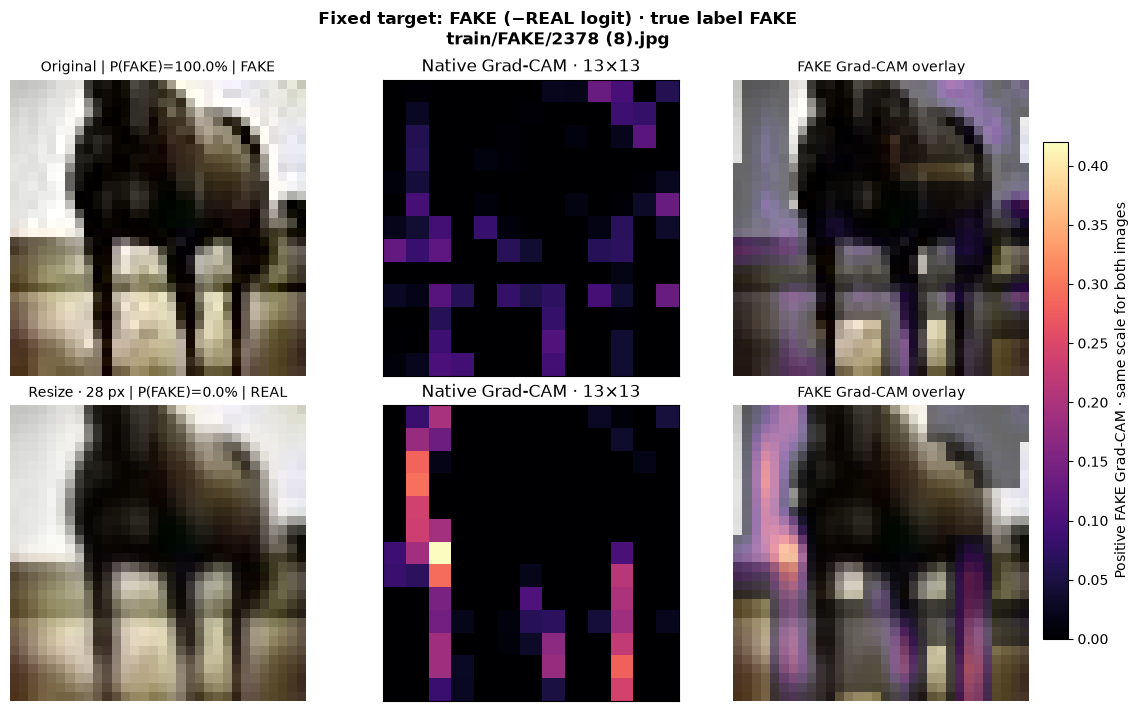

In [18]:
if explanation_default_pair is not None:
    finish_explanation_figure(
        gradcam_pair_figure(explanation_default_pair), "gradcam_fake_resize"
    )


For a second example, we will use the real image selected in the Phase I JPEG gallery and compare it with a quality-60 compressed version. This lets us inspect a change in the opposite direction: a real image receiving a higher FAKE probability. We will keep FAKE as the target in both rows, rather than switching the explanation to whichever class wins. The colour scale is shared within this pair, but is fitted separately from the resize example above. These are deliberately sensitive examples chosen from validation predictions, so they illustrate possible behaviour rather than its frequency across the dataset; `phase1/02_cnn_behaviour.ipynb` supplies the population-level results.

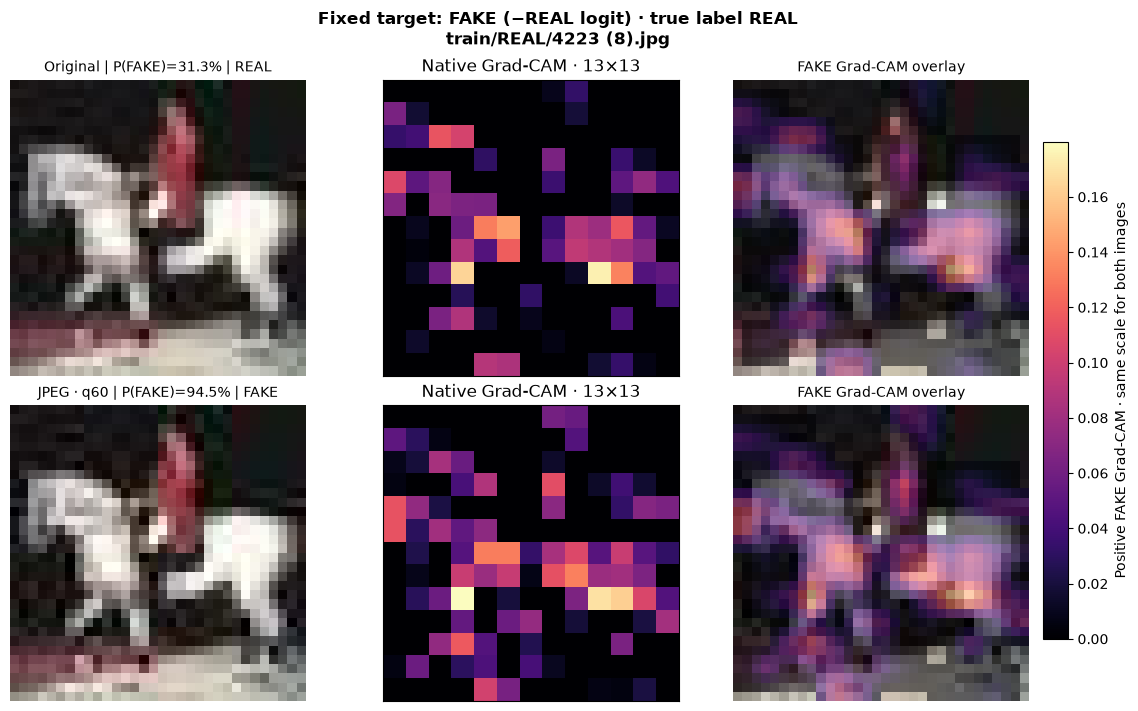

In [19]:
if explanation_comparison_pair is not None:
    finish_explanation_figure(
        gradcam_pair_figure(explanation_comparison_pair), "gradcam_real_jpeg"
    )


### 5.2 Neuron contributions: how do the weights produce the score?

Now we will return to the resize example and inspect the final decision directly. After the convolutions, this CNN has 64 hidden neurons. For a particular image, each neuron produces an activation $a_j$ and has a learned output weight $w_j$. Its contribution is **activation × weight**, and the output is exactly $z=b+\sum_{j=0}^{63}a_jw_j$. The weights and bias remain fixed when we edit an image; the activations change. A large weight alone therefore does not tell us how much a neuron contributes to this particular prediction.

The top heatmap shows all 64 contributions for the original and resized image on one shared scale: blue pushes the REAL logit up, while orange pushes it down toward FAKE. The bars underneath show the changes for the 12 neurons with the largest absolute changes, with the remaining 52 summed into a final bar. Together, all bars account for the complete change in logit; the unchanged bias cancels out. The small table then shows the actual activation and weight values for the six largest changes. Neuron numbers are identifiers, not labels such as “texture” or “background.”

In the default resize example, parts of the FAKE Grad-CAM map brighten even though the FAKE probability falls. This chart helps explain why we should not read heatmap brightness as confidence: the final decision combines all signed neuron contributions, including opposing evidence that a positive-only Grad-CAM map does not show. Probabilities in figure titles are rounded for readability; the logits reveal changes even when a displayed probability is close to 0% or 100%.

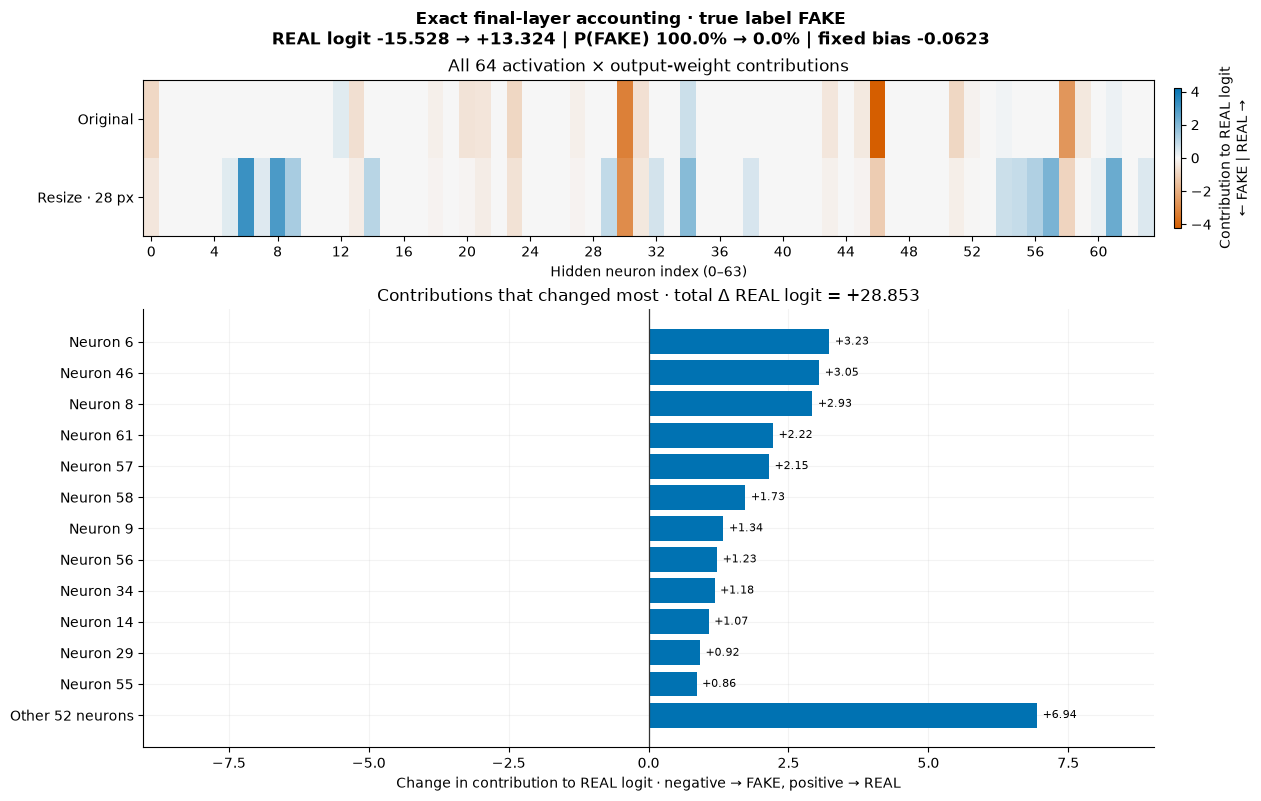

| Neuron | Fixed output weight | Activation: original | Activation: resized | Contribution: original | Contribution: resized | Change in REAL logit |
| --- | --- | --- | --- | --- | --- | --- |
| 6 | +0.7868 | 0.0000 | 4.1064 | +0.0000 | +3.2308 | +3.2308 |
| 46 | -1.1350 | 3.7370 | 1.0503 | -4.2414 | -1.1921 | +3.0493 |
| 8 | +0.9519 | 0.0000 | 3.0753 | +0.0000 | +2.9273 | +2.9273 |
| 61 | +0.6397 | 0.2685 | 3.7464 | +0.1718 | +2.3965 | +2.2247 |
| 57 | +0.5985 | 0.0000 | 3.5974 | +0.0000 | +2.1529 | +2.1529 |
| 58 | -0.7818 | 3.4224 | 1.2096 | -2.6757 | -0.9457 | +1.7300 |

| Image | Sum of 64 contributions | Fixed bias | Sum + bias | Model REAL logit |
| --- | --- | --- | --- | --- |
| Original | -15.46604 | -0.06231 | -15.52836 | -15.52836 |
| Resize · 28 px | +13.38669 | -0.06231 | +13.32437 | +13.32437 |

In [20]:
# Multiply each hidden activation by its output weight; include the bias to reconstruct the REAL logit.
if explanation_default_pair is not None:
    finish_explanation_figure(
        contribution_pair_figure(explanation_default_pair),
        "neuron_contributions_resize",
    )
    values = explanation_default_pair["values"]
    delta = (
        values["contribution_real"][1].astype(np.float64)
        - values["contribution_real"][0]
    )
    largest = np.argsort(-np.abs(delta), kind="stable")[:6]
    show_table(
        [
            "Neuron",
            "Fixed output weight",
            "Activation: original",
            "Activation: resized",
            "Contribution: original",
            "Contribution: resized",
            "Change in REAL logit",
        ],
        [
            (
                int(j),
                f"{values['weight64'][j]:+.4f}",
                f"{values['activation64'][0,j]:.4f}",
                f"{values['activation64'][1,j]:.4f}",
                f"{values['contribution_real'][0,j]:+.4f}",
                f"{values['contribution_real'][1,j]:+.4f}",
                f"{delta[j]:+.4f}",
            )
            for j in largest
        ],
    )
    sums = values["contribution_real"].sum(axis=1, dtype=np.float64)
    show_table(
        [
            "Image",
            "Sum of 64 contributions",
            "Fixed bias",
            "Sum + bias",
            "Model REAL logit",
        ],
        [
            (
                label,
                f"{sums[side]:+.5f}",
                f"{values['bias_real']:+.5f}",
                f"{sums[side]+values['bias_real']:+.5f}",
                f"{values['z_real'][side]:+.5f}",
            )
            for side, label in enumerate(["Original", "Resize · 28 px"])
        ],
    )


### 5.3 Occlusion: what happens when we cover a small region?

Here we will ask the model a direct “what if” question. We will slide a **4×4 patch in steps of two pixels** across the original and resized image, replacing all three colour channels in that patch. This gives 225 covered versions per image and reference colour. At each position we measure the FAKE score before covering minus the FAKE score afterwards. Orange means covering reduced the FAKE score, so that region supported FAKE relative to the chosen replacement; blue means covering increased the FAKE score. Pixels covered by several patches receive the average of those patch effects, so the map describes neighbourhoods rather than isolated pixel contributions.

The replacement itself can affect the result. We will therefore show two choices side by side: the original image's mean RGB colour and a neutral grey of 0.5 in each channel. Each reference is kept identical for the original and resized image, and all four maps share one symmetric colour scale. Agreement between the two columns gives more confidence that an effect is not specific to one fill colour, but it is still a response to an artificial intervention. Covering adds edges and changes local texture, especially at 32×32; it does not prove that a region contains a semantic object or that the model uses a particular shortcut.

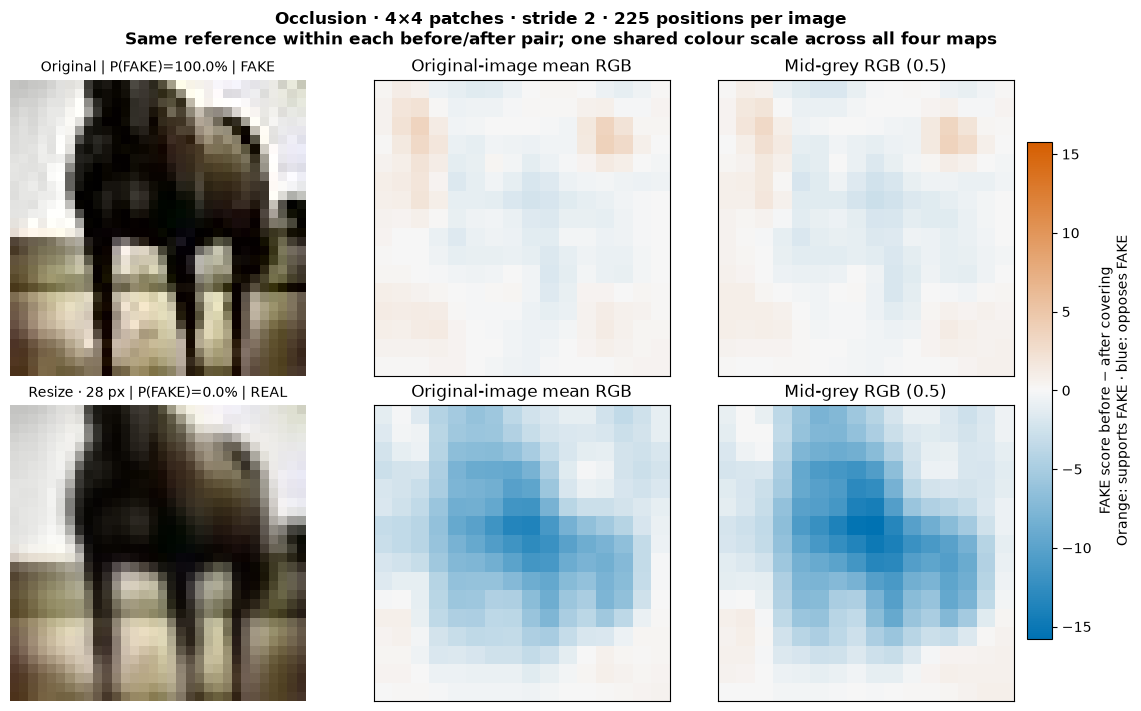

In [21]:
if explanation_default_pair is not None:
    finish_explanation_figure(
        occlusion_pair_figure(explanation_default_pair), "occlusion_fake_resize"
    )


### 5.4 Explore another image or modification

The controls below let us repeat all three views for any of the 27 included validation previews. Choose an image, a modification family, and a strength, then press **Explain pair**. Strength zero compares the original with itself, which is a useful check: its contribution changes should be zero. The patch control switches between 4×4 patches with stride two and 8×8 patches with stride four, so we can see whether a broad occlusion pattern persists at another scale. The tabs separate Grad-CAM, neuron contributions, and occlusion while keeping the same selected image pair.

This explorer computes explanations using the loaded model and caches results in memory. It needs a live notebook kernel; GitHub displays the static examples above. Changing a control marks the existing result as stale until we press the button again. The status line records the image and settings actually shown. These previews include sensitive cases and a seeded sample, so browsing them should generate hypotheses for a later controlled comparison rather than replace the full validation statistics.

In [22]:
if explanation_default_pair is not None:
    import html
    import ipywidgets as widgets

    explain_image_choice = widgets.Dropdown(
        options=[
            (
                f"{'FAKE' if behavior_labels[int(i)]==0 else 'REAL'} · {behavior_arrays['paths'][int(i)]}",
                int(i),
            )
            for i in behavior_arrays["preview_indices"]
        ],
        value=explanation_default_index,
        description="Image:",
        layout=widgets.Layout(width="95%"),
    )
    explain_family_choice = widgets.Dropdown(
        options=list(PROBE_FAMILIES), value="Resize", description="Change:"
    )
    explain_level_choice = widgets.IntSlider(
        value=1, min=0, max=4, description="Strength:", continuous_update=False
    )
    explain_patch_choice = widgets.Dropdown(
        options=[("4×4 · stride 2", 4), ("8×8 · stride 4", 8)],
        value=4,
        description="Patch:",
    )
    explain_button = widgets.Button(
        description="Explain pair", button_style="primary", icon="play"
    )
    explain_status = widgets.HTML()
    explain_details = widgets.HTML()
    explain_plot_widgets = [
        widgets.Image(format="png", layout=widgets.Layout(width="100%"))
        for _ in range(3)
    ]
    explain_tabs = widgets.Tab(children=explain_plot_widgets)
    for i, title in enumerate(["Grad-CAM", "Neuron contributions", "Occlusion"]):
        explain_tabs.set_title(i, title)
    explanation_explorer_state = {}

    def mark_explanation_stale(change=None):
        explain_status.value = "<b>Settings changed.</b> The plots still show the last computed pair. Press Explain pair to update."

    def update_explanation_explorer(button=None):
        explain_button.disabled = True
        explain_status.value = "Computing explanations…"
        try:
            index, family = int(explain_image_choice.value), explain_family_choice.value
            level, patch_size = int(explain_level_choice.value), int(
                explain_patch_choice.value
            )
            pair = get_explanation_pair(index, family, level, patch_size=patch_size)
            rendered = []
            for draw in [
                gradcam_pair_figure,
                contribution_pair_figure,
                occlusion_pair_figure,
            ]:
                fig = draw(pair)
                try:
                    stream = BytesIO()
                    fig.savefig(
                        stream,
                        format="png",
                        dpi=120,
                        bbox_inches="tight",
                        facecolor="white",
                    )
                    rendered.append(stream.getvalue())
                finally:
                    plt.close(fig)
            # Replace the plots together only after every view is ready.
            for target, png in zip(explain_plot_widgets, rendered):
                target.value = png
            p0, p1 = pair["values"]["p_fake"]
            explain_details.value = (
                f"<b>Showing: {pair['truth']}</b> · <code>{html.escape(pair['path'])}</code><br>"
                f"Original → {html.escape(pair['setting'])} · P(FAKE): {p0:.4%} → {p1:.4%}<br>"
                f"Occlusion: {patch_size}×{patch_size}, stride {pair['stride']} · "
                "Grad-CAM and occlusion target FAKE; neuron contributions target the REAL logit."
            )
            explanation_explorer_state.update(
                index=index,
                family=family,
                level=level,
                patch_size=patch_size,
                pair=pair,
            )
            explain_status.value = (
                "<b>Ready.</b> All three tabs show the pair recorded below."
            )
        except Exception as error:
            explain_status.value = f"<b>Could not update.</b> {html.escape(str(error))}. Any existing plots still show the previous result."
            raise
        finally:
            explain_button.disabled = False

    for control in [
        explain_image_choice,
        explain_family_choice,
        explain_level_choice,
        explain_patch_choice,
    ]:
        control.observe(mark_explanation_stale, names="value")
    explain_button.on_click(update_explanation_explorer)
    update_explanation_explorer()
    display(
        widgets.VBox(
            [
                explain_image_choice,
                widgets.HBox([explain_family_choice, explain_level_choice]),
                widgets.HBox([explain_patch_choice, explain_button]),
                explain_status,
                explain_details,
                explain_tabs,
            ]
        )
    )
    print(
        "Run this cell with a live kernel to explore. Static Grad-CAM, contribution and occlusion examples are saved above."
    )


Run this cell with a live kernel to explore. Static Grad-CAM, contribution and occlusion examples are saved above.


## 6. Inside the CNN: filters, responses and failure modes

We will now follow the earlier part of the decision process: **learned weights → feature maps → changes in the prediction**. The first convolution has 32 filters, each with a 3×3 slice for red, green and blue. Sliding these filters across the image gives 32 response maps. ReLU replaces negative responses with zero, and max pooling reduces their size. The second convolution then combines those 32 maps using another set of 32 filters. Each second-layer filter has 32 separate 3×3 slices, so its weights are not an RGB picture. The 64-neuron layer examined in Section 5 receives the features produced by this sequence.

The weights are fixed during this investigation. A filter is not assigned a name such as “edge detector” during training: we will examine its numbers, find image patches that activate it, and test a few controlled inputs before suggesting what it responds to. We will also switch off one output channel at a time, after its ReLU, to measure how that intervention changes predictions. This connects [feature visualization using dataset examples](https://distill.pub/2017/feature-visualization/) with [layer feature ablation](https://captum.ai/api/layer.html#layer-feature-ablation). A strong activation describes a response; the ablation test measures an effect on the output.

The aggregate investigation uses **2,000 validation images: 1,000 FAKE and 1,000 REAL, sampled without replacement with seed 20261103**. Every filter is tested on the same images in three conditions: original, resize 32→28→32, and JPEG quality 60. The last two were chosen because the Phase I probe showed different failure patterns under them. These sample results should not be confused with the full 10,000-image validation results in `phase1/02_cnn_behaviour.ipynb`. The saved probe and its selected example images are included below; `RUN_INTERNAL_PROBE = True` recomputes it when the prepared validation data are available.

The default filter in each layer is chosen by the largest drop in **clean sample accuracy** when its channel is zeroed. This gives us a useful starting point for inspection, but is an exploratory selection on this sample. It does not establish that a filter has a universal meaning, nor that removing it would be a good model change.

**Following and editing feature maps.** These helpers expose the CNN intermediates and continue the forward pass after a selected channel has been zeroed. This lets us test the effect of an intervention, rather than only looking at a response map.

In [23]:
INTERNAL_SEED = 20261103
INTERNAL_PER_CLASS = 1000
INTERNAL_LAYERS = [
    {
        "name": "Conv 1",
        "activation_index": 1,
        "weight_index": 0,
        "map_size": 30,
        "receptive_field": 3,
        "jump": 1,
    },
    {
        "name": "Conv 2",
        "activation_index": 4,
        "weight_index": 3,
        "map_size": 13,
        "receptive_field": 8,
        "jump": 2,
    },
]


@torch.inference_mode()
def internal_forward(net, images, selected_device):
    """Return post-ReLU maps and REAL logits using the actual baseline modules."""
    if not isinstance(net, BaselineCNN):
        raise TypeError("The filter investigation is specific to BaselineCNN.")
    net.eval()
    x = (
        torch.tensor(
            np.ascontiguousarray(images), device=selected_device, dtype=torch.float32
        )
        / 255
    )
    first = net.features[:2](x)
    second = net.features[3:5](net.features[2](first))
    logits = net.classifier(net.features[5](second)).squeeze(1)
    return [first, second], logits


@torch.inference_mode()
def internal_continue(net, activation, layer_index):
    """Continue the forward pass from a feature map that we may have edited."""
    remaining = net.features[INTERNAL_LAYERS[layer_index]["activation_index"] + 1 :]
    return net.classifier(remaining(activation)).squeeze(1)


@torch.inference_mode()
def internal_ablate_channels(net, activation, layer_index):
    """Zero one complete post-ReLU channel at a time; retain every other channel."""
    results = []
    for channel in range(activation.shape[1]):
        edited = activation.clone()
        edited[:, channel] = 0
        results.append(internal_continue(net, edited, layer_index).cpu().numpy())
    return np.stack(results)


**The fixed internal experiment.** We use a seeded, balanced validation sample for clean, resized and JPEG inputs. The resulting responses and interventions are saved so teammates can inspect them without recomputing the full experiment.

In [24]:
def run_internal_probe(
    net, data_dir, selected_device, expected_manifest, batch_size=128
):
    """Use a fixed balanced validation sample to compare channels across image conditions."""
    started = time.perf_counter()
    if file_sha256(data_dir / "manifest.csv") != expected_manifest:
        raise ValueError("The validation split does not match the selected checkpoint.")
    images, labels, rows = load_split(data_dir, "val")
    assert all(row["split"] == "val" and row["source_split"] == "train" for row in rows)
    rng = np.random.default_rng(INTERNAL_SEED)
    indices = np.sort(
        np.concatenate(
            [
                rng.choice(
                    np.flatnonzero(labels == label), INTERNAL_PER_CLASS, replace=False
                )
                for label in [0, 1]
            ]
        )
    ).astype(np.int32)
    n = len(indices)
    cohort = np.asarray(images[indices])
    conditions = [
        {"name": "Original", "family": "Original", "value": None},
        {"name": "Resize 32→28→32", "family": "Resize", "value": 28},
        {"name": "JPEG quality 60", "family": "JPEG", "value": 60},
    ]
    digest = behavior_model_digest(net)
    logits = np.empty((3, n), dtype=np.float32)
    ablated = np.empty((3, 2, 32, n), dtype=np.float32)
    mean_activation = np.empty((3, 2, 32, n), dtype=np.float32)
    zero_fraction = np.empty_like(mean_activation)
    peak_activation = np.empty((2, 32, n), dtype=np.float32)
    peak_position = np.empty((2, 32, n, 2), dtype=np.int16)
    for ci, condition in enumerate(conditions):
        modified = np.stack(
            [
                modify_behavior_image(
                    im, condition["family"], condition["value"], int(i)
                )
                for im, i in zip(cohort, indices)
            ]
        )
        for start in range(0, n, batch_size):
            stop = min(start + batch_size, n)
            maps, z = internal_forward(net, modified[start:stop], selected_device)
            logits[ci, start:stop] = z.cpu().numpy()
            for li, activation in enumerate(maps):
                ablated[ci, li, :, start:stop] = internal_ablate_channels(
                    net, activation, li
                )
                mean_activation[ci, li, :, start:stop] = (
                    activation.mean((2, 3)).cpu().numpy().T
                )
                zero_fraction[ci, li, :, start:stop] = (
                    (activation == 0).float().mean((2, 3)).cpu().numpy().T
                )
                if ci == 0:
                    flat = activation.flatten(2)
                    peak, where = flat.max(2)
                    peak_activation[li, :, start:stop] = peak.cpu().numpy().T
                    pos = where.cpu().numpy().T
                    peak_position[li, :, start:stop, 0] = pos // activation.shape[-1]
                    peak_position[li, :, start:stop, 1] = pos % activation.shape[-1]
            if start == 0 or stop == n or stop % 512 == 0:
                print(
                    f"{condition['name']}: {stop:,}/{n:,} images · both layers, all 32 channels",
                    flush=True,
                )
        accuracy = ((logits[ci] >= 0) == labels[indices]).mean()
        print(f"  Unablated accuracy: {accuracy:.2%}", flush=True)
    # Stable order makes tied activations reproducible; ties are not evidence of preference.
    top_slots = np.argsort(-peak_activation, axis=2, kind="stable")[:, :, :3].astype(
        np.int32
    )
    example_indices = np.unique(indices[top_slots]).astype(np.int32)
    arrays = {
        "indices": indices,
        "labels": labels[indices].astype(np.int8),
        "paths": np.asarray([rows[int(i)]["path"] for i in indices]),
        "logits_real": logits,
        "ablated_logits_real": ablated,
        "mean_activation": mean_activation.mean(-1),
        "zero_fraction": zero_fraction.mean(-1),
        "class_mean_activation": np.stack(
            [
                mean_activation[:, :, :, labels[indices] == label].mean(-1)
                for label in [0, 1]
            ],
            axis=-1,
        ),
        "top_peak_activation": np.take_along_axis(peak_activation, top_slots, axis=2),
        "top_position": peak_position[
            np.arange(2)[:, None, None], np.arange(32)[None, :, None], top_slots
        ],
        "top_slots": top_slots,
        "example_indices": example_indices,
        "example_images": np.asarray(images[example_indices]),
    }
    assert behavior_model_digest(net) == digest
    metadata = {
        "split": "val",
        "seed": INTERNAL_SEED,
        "per_class": INTERNAL_PER_CLASS,
        "n": n,
        "model_state_sha256": digest,
        "manifest_sha256": expected_manifest,
        "cohort_pixels_sha256": hashlib.sha256(cohort.tobytes()).hexdigest(),
        "conditions": conditions,
        "layers": INTERNAL_LAYERS,
        "intervention": "Set all spatial positions of one channel to zero after its ReLU, before pooling.",
        "top_examples": "Three highest spatial maxima per channel among original cohort images; stable tie order.",
        "elapsed_seconds": time.perf_counter() - started,
        "environment": {
            "torch": str(torch.__version__),
            "numpy": np.__version__,
            "pillow": importlib.metadata.version("pillow"),
            "device": str(selected_device),
        },
    }
    return arrays, metadata


def internal_metrics(arrays, bootstrap_draws=2000):
    labels = arrays["labels"]
    predicted = arrays["logits_real"] >= 0
    removed = arrays["ablated_logits_real"] >= 0
    correct = predicted == labels[None, :]
    removed_correct = removed == labels[None, None, None, :]
    harm = correct[:, None, None, :] & ~removed_correct
    repair = ~correct[:, None, None, :] & removed_correct
    drop = harm.mean(-1) - repair.mean(-1)
    rng = np.random.default_rng(INTERNAL_SEED + 1)
    interval = np.empty(drop.shape + (2,), dtype=np.float64)
    for ci in range(drop.shape[0]):
        for li in range(2):
            for channel in range(32):
                draws = np.zeros(bootstrap_draws)
                for label in [0, 1]:
                    select = labels == label
                    h = int(harm[ci, li, channel, select].sum())
                    r = int(repair[ci, li, channel, select].sum())
                    n = int(select.sum())
                    simulated = rng.multinomial(
                        n, [h / n, r / n, (n - h - r) / n], size=bootstrap_draws
                    )
                    draws += simulated[:, 0] - simulated[:, 1]
                interval[ci, li, channel] = np.quantile(
                    draws / len(labels), [0.025, 0.975]
                )
    return {
        "accuracy": correct.mean(-1),
        "ablated_accuracy": removed_correct.mean(-1),
        "drop": drop,
        "interval": interval,
        "harm": harm.sum(-1),
        "repair": repair.sum(-1),
        "fake_detected": (~predicted[:, labels == 0]).mean(-1),
        "real_false_alarm": (~predicted[:, labels == 1]).mean(-1),
        "ablated_fake_detected": (~removed[:, :, :, labels == 0]).mean(-1),
        "ablated_real_false_alarm": (~removed[:, :, :, labels == 1]).mean(-1),
    }


internal_pair_cache = {}


def get_internal_pair(index, family, level):
    """Collect the original and modified feature maps for the selected preview image."""
    index, level = int(index), int(level)
    condition = behavior_conditions_list[behavior_groups[family][level]]
    original = behavior_previews[index]
    changed = modify_behavior_image(
        original, condition["family"], condition["value"], index
    )
    images = np.stack([original, changed])
    key = (behavior_model_digest(model), hashlib.sha256(images.tobytes()).hexdigest())
    if key not in internal_pair_cache:
        maps, z = internal_forward(model, images, device)
        removed = np.stack(
            [internal_ablate_channels(model, m, li) for li, m in enumerate(maps)]
        )
        internal_pair_cache[key] = {
            "images": images,
            "maps": [m.cpu().numpy().copy() for m in maps],
            "logits_real": z.cpu().numpy().copy(),
            "ablated_logits_real": removed,
        }
    result = dict(internal_pair_cache[key])
    result.update(
        index=index,
        family=family,
        level=level,
        setting="Original" if level == 0 else f"{family} · {condition['label']}",
        path=str(behavior_arrays["paths"][index]),
        truth="FAKE" if behavior_labels[index] == 0 else "REAL",
    )
    return result


**Saved review data.** The trained weights and saved measurements are stored in notebook metadata, so there is no long encoded string to scroll through. This short loader checks and decodes the data when needed. Keep the complete `.ipynb` file when sharing it.

In [25]:
# Saved internal probe and top-activation examples; no dataset download or training is performed.
INTERNAL_REPORT = {
    "split": "val",
    "seed": 20261103,
    "per_class": 1000,
    "n": 2000,
    "model_state_sha256": "2b73e9f88f029ae7f9d33935864ceeefbd443b7d80a87e532301909a3c0a90a8",
    "manifest_sha256": "098210d89f9441376008d520f72aeef5f65a7aa6b5e0073ba4e875c979e1f205",
    "cohort_pixels_sha256": "b87e0ccb3e154156e90d62e6e4de1380f827fba93403726fe5fd964b75880694",
    "conditions": [
        {"name": "Original", "family": "Original", "value": None},
        {"name": "Resize 32→28→32", "family": "Resize", "value": 28},
        {"name": "JPEG quality 60", "family": "JPEG", "value": 60},
    ],
    "layers": [
        {
            "name": "Conv 1",
            "activation_index": 1,
            "weight_index": 0,
            "map_size": 30,
            "receptive_field": 3,
            "jump": 1,
        },
        {
            "name": "Conv 2",
            "activation_index": 4,
            "weight_index": 3,
            "map_size": 13,
            "receptive_field": 8,
            "jump": 2,
        },
    ],
    "intervention": "Set all spatial positions of one channel to zero after its ReLU, before pooling.",
    "top_examples": "Three highest spatial maxima per channel among original cohort images; stable tie order.",
    "elapsed_seconds": 3.5533366668969393,
    "environment": {
        "torch": "2.15.0",
        "numpy": "2.5.4",
        "pillow": "13.0.0",
        "device": "mps",
    },
}
INTERNAL_BUNDLE_SHA256 = (
    "65118d937f6be5afe9d24bb787f60369edfb32ad78b6007e3f22583b49c5e8c8"
)
INTERNAL_PAYLOAD = notebook_payload("baseline_internal_bundle")


def load_internal_bundle():
    """Restore the saved channel experiments and verify their shapes and sample balance."""
    raw = base64.b64decode(INTERNAL_PAYLOAD)
    if hashlib.sha256(raw).hexdigest() != INTERNAL_BUNDLE_SHA256:
        raise ValueError("The internal probe payload failed its integrity check.")
    with np.load(BytesIO(raw), allow_pickle=False) as packed:
        arrays = {key: packed[key] for key in packed.files}
    report = dict(INTERNAL_REPORT)
    n = report["n"]
    assert arrays["logits_real"].shape == (3, n)
    assert arrays["ablated_logits_real"].shape == (3, 2, 32, n)
    assert np.isfinite(arrays["ablated_logits_real"]).all()
    assert len(np.unique(arrays["indices"])) == n
    assert all(
        int((arrays["labels"] == label).sum()) == report["per_class"]
        for label in [0, 1]
    )
    assert arrays["top_slots"].shape == (2, 32, 3) and arrays["top_position"].shape == (
        2,
        32,
        3,
        2,
    )
    return arrays, report


In [26]:
# Load the fixed validation sample and saved channel interventions for the selected CNN.
internal_arrays, internal_report, internal_stats = None, None, None
internal_default_pair = None
internal_examples = {}
if isinstance(model, BaselineCNN) and behavior_arrays is not None:
    expected_manifest = checkpoint.get(
        "manifest_sha256", checkpoint.get("config", {}).get("manifest_sha256")
    )
    if RUN_INTERNAL_PROBE:
        internal_arrays, internal_report = run_internal_probe(
            model, DATA_DIR, device, expected_manifest
        )
    else:
        candidate_arrays, candidate_report = load_internal_bundle()
        if (
            behavior_model_digest(model) == candidate_report["model_state_sha256"]
            and expected_manifest == candidate_report["manifest_sha256"]
        ):
            internal_arrays, internal_report = candidate_arrays, candidate_report
        else:
            print(
                "The saved internal probe belongs to another model or split. Enable RUN_INTERNAL_PROBE after preparing a matching validation probe."
            )
    if internal_arrays is not None:
        internal_stats = internal_metrics(internal_arrays)
        internal_examples = {
            int(i): im
            for i, im in zip(
                internal_arrays["example_indices"], internal_arrays["example_images"]
            )
        }
        internal_default_channel = int(np.argmax(internal_stats["drop"][0, 0]))
        internal_second_channel = int(np.argmax(internal_stats["drop"][0, 1]))
        internal_default_pair = get_internal_pair(
            behavior_report["gallery_indices"]["Resize"]["FAKE"], "Resize", 1
        )
        print(
            f"Loaded internal investigation: {internal_report['n']:,} validation images, three conditions, both convolutional layers."
        )
        print(
            f"Clean-accuracy selection: Conv 1 filter {internal_default_channel}; Conv 2 filter {internal_second_channel}."
        )
        print(
            "Source paths retain the original train/ prefix; all selected images belong to our held-out validation split."
        )
        show_table(
            [
                "Condition",
                "Sample accuracy",
                "Fake images detected",
                "Real images incorrectly flagged",
            ],
            [
                (
                    condition["name"],
                    f"{internal_stats['accuracy'][ci]:.2%}",
                    f"{internal_stats['fake_detected'][ci]:.2%}",
                    f"{internal_stats['real_false_alarm'][ci]:.2%}",
                )
                for ci, condition in enumerate(internal_report["conditions"])
            ],
        )
else:
    print(
        "Load a BaselineCNN and its matching validation probe in Sections 3 and 4 before inspecting filters."
    )


Loaded internal investigation: 2,000 validation images, three conditions, both convolutional layers.
Clean-accuracy selection: Conv 1 filter 11; Conv 2 filter 25.
Source paths retain the original train/ prefix; all selected images belong to our held-out validation split.


| Condition | Sample accuracy | Fake images detected | Real images incorrectly flagged |
| --- | --- | --- | --- |
| Original | 94.80% | 94.90% | 5.30% |
| Resize 32→28→32 | 63.80% | 27.80% | 0.20% |
| JPEG quality 60 | 90.90% | 98.90% | 17.10% |

**Weights and convolution arithmetic.** These views turn the learned numbers into filter grids and a worked convolution example. They show how an input patch produces a channel response.

In [27]:
from matplotlib.patches import Rectangle


def internal_pfake(logits):
    return np.exp(-np.logaddexp(0, np.asarray(logits, dtype=np.float64)))


def internal_weight_figure(layer_index=0, channel=0):
    layer = INTERNAL_LAYERS[layer_index]
    weights = model.features[layer["weight_index"]].weight.detach().cpu().numpy()
    bias = model.features[layer["weight_index"]].bias.detach().cpu().numpy()
    panels = (
        [np.concatenate(list(w), axis=1) for w in weights]
        if layer_index == 0
        else list(weights[channel])
    )
    vmax = max(float(np.max(np.abs(panels))), 1e-9)
    fig, axes = plt.subplots(8, 4, figsize=(12, 10), layout="constrained")
    for i, ax in enumerate(axes.flat):
        heat = ax.imshow(
            panels[i], cmap="RdBu_r", vmin=-vmax, vmax=vmax, interpolation="nearest"
        )
        ax.set_yticks([])
        if layer_index == 0:
            ax.set_xticks([1, 4, 7], ["R", "G", "B"], fontsize=8)
            for x in [2.5, 5.5]:
                ax.axvline(x, color="#777777", lw=0.6)
            ax.set_title(f"Output filter {i} · bias {bias[i]:+.2f}", fontsize=8)
            if i == channel:
                for spine in ax.spines.values():
                    spine.set_color("#18985b")
                    spine.set_linewidth(2)
        else:
            ax.set_xticks([])
            ax.set_title(f"Input channel {i}", fontsize=8)
    colorbar = fig.colorbar(heat, ax=list(axes.flat), shrink=0.75, pad=0.01)
    colorbar.set_label("Learned weight · red positive, blue negative · shared scale")
    title = (
        f"Conv 1: all 32 learned filters · three 3×3 RGB slices per filter\nSelected filter {channel} is outlined in green"
        if layer_index == 0
        else f"Conv 2, output filter {channel}: 32 learned 3×3 input-channel slices · bias {bias[channel]:+.3f}"
    )
    fig.suptitle(title, fontsize=12, fontweight="bold")
    return fig


def internal_operation_values(pair, layer_index, channel, side=0):
    """Work through the multiply-and-add calculation for one convolution response."""
    layer = INTERNAL_LAYERS[layer_index]
    activation = pair["maps"][layer_index][side, channel]
    y, x = np.unravel_index(np.argmax(activation), activation.shape)
    with torch.inference_mode():
        image = (
            torch.tensor(
                pair["images"][side : side + 1], device=device, dtype=torch.float32
            )
            / 255
        )
        inputs = image if layer_index == 0 else model.features[:3](image)
        conv = model.features[layer["weight_index"]]
        expected_pre = float(conv(inputs)[0, channel, y, x].cpu())
        window = inputs[0, :, y : y + 3, x : x + 3].cpu().numpy().copy()
        weights = conv.weight[channel].detach().cpu().numpy().copy()
        bias = float(conv.bias[channel].cpu())
    product = window.astype(np.float64) * weights
    pre = float(product.sum() + bias)
    assert np.isclose(pre, expected_pre, atol=3e-5, rtol=1e-5)
    assert np.isclose(max(0, pre), activation[y, x], atol=3e-5, rtol=1e-5)
    return {
        "window": window,
        "weights": weights,
        "product": product,
        "bias": bias,
        "pre": pre,
        "activation": float(activation[y, x]),
        "position": (int(y), int(x)),
    }


def internal_operation_figure(pair, layer_index, channel):
    result = internal_operation_values(pair, layer_index, channel)
    n = result["window"].shape[0]
    selected = (
        np.arange(3)
        if n == 3
        else np.argsort(-np.abs(result["product"].sum((1, 2))), kind="stable")[:3]
    )
    remainder = float(result["product"].sum() - result["product"][selected].sum())
    fig, axes = plt.subplots(3, 3, figsize=(9.5, 8), layout="constrained")
    for row, ch in enumerate(selected):
        for col, key in enumerate(["window", "weights", "product"]):
            matrix = result[key][ch]
            limit = max(float(np.max(np.abs(result[key]))), 1e-9)
            ax = axes[row, col]
            ax.imshow(
                matrix,
                cmap="gray" if col == 0 else "RdBu_r",
                vmin=0 if col == 0 else -limit,
                vmax=limit,
                interpolation="nearest",
            )
            for y in range(3):
                for x in range(3):
                    light_text = (
                        (matrix[y, x] < 0.45 * limit)
                        if col == 0
                        else (abs(matrix[y, x]) > 0.6 * limit)
                    )
                    ax.text(
                        x,
                        y,
                        f"{matrix[y,x]:.3f}",
                        ha="center",
                        va="center",
                        fontsize=9,
                        color="white" if light_text else "#111111",
                    )
            name = "RGB"[ch] if n == 3 else f"Input channel {ch}"
            ax.set(
                title=f"{name} · {['input values','learned weights','input × weight'][col]}",
                xticks=[],
                yticks=[],
            )
    fig.suptitle(
        f"{INTERNAL_LAYERS[layer_index]['name']}, filter {channel} · ORIGINAL image · map position {result['position']}\n"
        f"Sum of all products {result['product'].sum():+.4f} + bias {result['bias']:+.4f} = {result['pre']:+.4f}\n"
        f"ReLU keeps max(0, value) = {result['activation']:.4f}"
        + (
            f"\nOnly three input channels shown; the other 29 product sums total {remainder:+.4f}."
            if n > 3
            else ""
        ),
        fontsize=11,
        fontweight="bold",
    )
    return fig


**Responses and activating examples.** These plots compare original and modified feature maps and show the image patches with the strongest saved responses for a selected channel.

In [28]:
def internal_activation_figure(pair, layer_index):
    maps = pair["maps"][layer_index]
    maximum = max(float(maps.max()), 1e-9)
    fig, axes = plt.subplots(8, 4, figsize=(13, 10), layout="constrained")
    cmap = plt.get_cmap("magma").copy()
    cmap.set_bad("white")
    for ch, ax in enumerate(axes.flat):
        joined = np.concatenate(
            [maps[0, ch], np.full((maps.shape[-1], 1), np.nan), maps[1, ch]], axis=1
        )
        heat = ax.imshow(
            joined, cmap=cmap, vmin=0, vmax=maximum, interpolation="nearest"
        )
        ax.set(
            title=f"Filter {ch} · mean {maps[0,ch].mean():.2f} → {maps[1,ch].mean():.2f}",
            xticks=[],
            yticks=[],
        )
        ax.title.set_fontsize(8)
    bar = fig.colorbar(heat, ax=list(axes.flat), shrink=0.8, pad=0.01)
    bar.set_label(
        "Post-ReLU activation · same scale across all filters and both images"
    )
    fig.suptitle(
        f"{INTERNAL_LAYERS[layer_index]['name']} · all 32 feature maps\n"
        f"Left of each divider: original · right: {pair['setting']} · true label {pair['truth']}\n{pair['path']}",
        fontsize=11,
        fontweight="bold",
    )
    return fig


def internal_detail_figure(pair, layer_index, channel):
    layer = INTERNAL_LAYERS[layer_index]
    maps = pair["maps"][layer_index][:, channel]
    vmax = max(float(maps.max()), 1e-9)
    fig, axes = plt.subplots(2, 3, figsize=(11, 7), layout="constrained")
    for side in range(2):
        y, x = np.unravel_index(np.argmax(maps[side]), maps[side].shape)
        py, px = int(y) * layer["jump"], int(x) * layer["jump"]
        r = layer["receptive_field"]
        p = float(internal_pfake(pair["logits_real"][side]))
        removed = float(
            internal_pfake(pair["ablated_logits_real"][layer_index, channel, side])
        )
        label = "Original" if side == 0 else pair["setting"]
        explanation_image(
            axes[side, 0],
            pair["images"][side],
            f"{label} · P(FAKE) {p:.2%}\nWith this channel zeroed: {removed:.2%}",
        )
        axes[side, 0].add_patch(
            Rectangle(
                (px - 0.5, py - 0.5), r, r, fill=False, edgecolor="#00ff88", lw=1.5
            )
        )
        heat = axes[side, 1].imshow(
            maps[side], cmap="magma", vmin=0, vmax=vmax, interpolation="nearest"
        )
        axes[side, 1].set(
            title=f"Filter {channel} · peak {maps[side,y,x]:.3f}", xticks=[], yticks=[]
        )
        axes[side, 1].add_patch(
            Rectangle((x - 0.5, y - 0.5), 1, 1, fill=False, edgecolor="#00ff88", lw=1.2)
        )
        crop = pair["images"][side, :, py : py + r, px : px + r]
        explanation_image(
            axes[side, 2],
            crop,
            f"Input region for the peak · {r}×{r}\nGreen box in the input image",
        )
        if not np.any(maps[side] > 0):
            axes[side, 1].text(
                0.5,
                0.5,
                "No positive response\nAll positions tied at zero",
                transform=axes[side, 1].transAxes,
                ha="center",
                va="center",
                color="white",
                fontsize=9,
            )
    bar = fig.colorbar(heat, ax=list(axes[:, 1]), shrink=0.7, pad=0.02)
    bar.set_label("Activation · shared before/after scale")
    fig.suptitle(
        f"{layer['name']}, filter {channel} · true label {pair['truth']}\n{pair['path']}\n"
        "A bright response is not itself evidence for REAL or FAKE; the zero-channel test measures an output effect.",
        fontsize=11,
        fontweight="bold",
    )
    return fig


internal_example_cache = {}


def internal_top_examples_figure(layer_index, channel):
    layer = INTERNAL_LAYERS[layer_index]
    slots = internal_arrays["top_slots"][layer_index, channel]
    ids = internal_arrays["indices"][slots]
    key = (behavior_model_digest(model), layer_index, channel, tuple(ids))
    if key not in internal_example_cache:
        images = np.stack([internal_examples[int(i)] for i in ids])
        maps, z = internal_forward(model, images, device)
        internal_example_cache[key] = (
            images,
            maps[layer_index][:, channel].cpu().numpy().copy(),
            z.cpu().numpy().copy(),
        )
    images, maps, z = internal_example_cache[key]
    peaks = internal_arrays["top_peak_activation"][layer_index, channel]
    np.testing.assert_allclose(maps.max((1, 2)), peaks, atol=3e-5, rtol=1e-5)
    fig, axes = plt.subplots(3, 3, figsize=(10.5, 9), layout="constrained")
    vmax = max(float(maps.max()), 1e-9)
    for row, (image, slot) in enumerate(zip(images, slots)):
        y, x = map(int, internal_arrays["top_position"][layer_index, channel, row])
        py, px = y * layer["jump"], x * layer["jump"]
        r = layer["receptive_field"]
        truth = "FAKE" if internal_arrays["labels"][slot] == 0 else "REAL"
        path = Path(str(internal_arrays["paths"][slot])).name
        explanation_image(
            axes[row, 0],
            image,
            f"Rank {row+1} · {truth} · {path}\nP(FAKE) {float(internal_pfake(z[row])):.2%}",
        )
        axes[row, 0].add_patch(
            Rectangle(
                (px - 0.5, py - 0.5), r, r, fill=False, edgecolor="#00ff88", lw=1.5
            )
        )
        heat = axes[row, 1].imshow(
            maps[row], cmap="magma", vmin=0, vmax=vmax, interpolation="nearest"
        )
        axes[row, 1].set(
            title=f"Peak activation {peaks[row]:.3f}", xticks=[], yticks=[]
        )
        axes[row, 1].add_patch(
            Rectangle((x - 0.5, y - 0.5), 1, 1, fill=False, edgecolor="#00ff88", lw=1.2)
        )
        explanation_image(
            axes[row, 2],
            image[:, py : py + r, px : px + r],
            f"{r}×{r} input region for this peak",
        )
    bar = fig.colorbar(heat, ax=list(axes[:, 1]), shrink=0.7, pad=0.02)
    bar.set_label("Post-ReLU activation · shared scale")
    suffix = (
        "\nAll peaks are zero: these tied examples do not show a preferred pattern."
        if not np.any(peaks > 0)
        else ""
    )
    fig.suptitle(
        f"{layer['name']}, filter {channel} · three strongest spatial responses\n"
        f"Original images from the {internal_report['n']:,}-image validation sample; selected by activation, not prediction accuracy.{suffix}",
        fontsize=11,
        fontweight="bold",
    )
    return fig


**Interventions and pattern checks.** The ablation view counts the effect of removing a channel. Simple synthetic patterns provide a limited check of a visual interpretation; they do not assign a semantic meaning to the filter.

In [29]:
def internal_ablation_figure():
    stats = internal_stats
    fig, axes = plt.subplots(
        2, 3, figsize=(14, 14), sharex=True, sharey="row", layout="constrained"
    )
    extent = max(float(np.abs(stats["interval"]).max() * 100) * 1.08, 1)
    for li in range(2):
        order = np.argsort(-stats["drop"][0, li], kind="stable")
        for ci in range(3):
            ax = axes[li, ci]
            values = 100 * stats["drop"][ci, li, order]
            bounds = 100 * stats["interval"][ci, li, order]
            for row, (value, bound) in enumerate(zip(values, bounds)):
                color = "#0072B2" if value >= 0 else "#D55E00"
                ax.plot(bound, [row, row], color=color, lw=1.2, alpha=0.65)
                ax.scatter(value, row, color=color, s=18, zorder=3)
            ax.axvline(0, color="#333333", lw=0.8)
            ax.set(
                yticks=np.arange(32),
                yticklabels=[str(j) for j in order],
                xlim=(-extent, extent),
                title=f"{INTERNAL_LAYERS[li]['name']} · {internal_report['conditions'][ci]['name']}\nUnablated accuracy {stats['accuracy'][ci]:.2%}",
                xlabel="Accuracy lost when channel is zeroed (pp)",
            )
            ax.tick_params(axis="y", labelsize=8)
            ax.tick_params(axis="x", labelbottom=True)
            if ci == 0:
                ax.set_ylabel("Filter index · ordered by effect on clean accuracy")
            behavior_axes_style(ax)
        axes[li, 0].invert_yaxis()
    fig.suptitle(
        f"Single-channel ablation on the same {internal_report['n']:,} validation images\n"
        "Positive / blue: removal hurts accuracy · negative / orange: removal improves accuracy\n"
        "Lines: 95% pointwise paired-bootstrap intervals; exploratory comparisons, no multiple-comparison adjustment.",
        fontsize=12,
        fontweight="bold",
    )
    return fig


def internal_channel_rows(layer_index, channel):
    rows = []
    for ci, condition in enumerate(internal_report["conditions"]):
        rows.append(
            (
                condition["name"],
                f"{internal_stats['accuracy'][ci]:.2%}",
                f"{internal_stats['ablated_accuracy'][ci,layer_index,channel]:.2%}",
                f"{100*internal_stats['drop'][ci,layer_index,channel]:+.2f}",
                int(internal_stats["harm"][ci, layer_index, channel]),
                int(internal_stats["repair"][ci, layer_index, channel]),
                f"{internal_stats['fake_detected'][ci]:.1%} → {internal_stats['ablated_fake_detected'][ci,layer_index,channel]:.1%}",
                f"{internal_stats['real_false_alarm'][ci]:.1%} → {internal_stats['ablated_real_false_alarm'][ci,layer_index,channel]:.1%}",
            )
        )
    return rows


def internal_test_patterns():
    """Probe simple synthetic patterns to help interpret a filter response."""
    y, x = np.indices((32, 32))
    patterns = [
        ("Black", np.zeros((32, 32))),
        ("Grey", np.full((32, 32), 128)),
        ("White", np.full((32, 32), 255)),
        ("Light → dark", 255 * (x < 16)),
        ("Dark → light", 255 * (x >= 16)),
        ("Light ↓ dark", 255 * (y < 16)),
        ("Dark ↓ light", 255 * (y >= 16)),
        ("Checkerboard", 255 * ((x + y) % 2)),
    ]
    images = np.stack(
        [np.repeat(np.asarray(p, dtype=np.uint8)[None], 3, axis=0) for _, p in patterns]
    )
    return [name for name, _ in patterns], images


def internal_pattern_figure(layer_index, channel):
    names, images = internal_test_patterns()
    maps, _ = internal_forward(model, images, device)
    responses = maps[layer_index][:, channel].cpu().numpy()
    vmax = max(float(responses.max()), 1e-9)
    fig, axes = plt.subplots(2, 8, figsize=(15, 4.8), layout="constrained")
    for i, name in enumerate(names):
        explanation_image(axes[0, i], images[i], name)
        for spine in axes[0, i].spines.values():
            spine.set_visible(True)
            spine.set_color("#999999")
            spine.set_linewidth(0.7)
        heat = axes[1, i].imshow(
            responses[i], cmap="magma", vmin=0, vmax=vmax, interpolation="nearest"
        )
        axes[1, i].set(
            title=f"Peak {responses[i].max():.3f}\nMean {responses[i].mean():.3f}",
            xticks=[],
            yticks=[],
        )
        axes[1, i].title.set_fontsize(9)
    bar = fig.colorbar(heat, ax=list(axes[1]), shrink=0.8, pad=0.01)
    bar.set_label("Activation")
    fig.suptitle(
        f"Controlled synthetic inputs · {INTERNAL_LAYERS[layer_index]['name']}, filter {channel}\n"
        "Identical RGB channels isolate brightness patterns. These are diagnostic inputs, not an accuracy benchmark.",
        fontsize=12,
        fontweight="bold",
    )
    return fig


INTERNAL_TABLE_HEADERS = [
    "Condition",
    "Accuracy: intact",
    "Accuracy: zeroed",
    "Accuracy lost (pp)",
    "New mistakes",
    "Mistakes repaired",
    "Fake detected: intact → zeroed",
    "Real false alarms: intact → zeroed",
]


def finish_internal_figure(fig, name):
    if SAVE_FIGURES:
        directory = ROOT / "results" / f"{RUN_NAME}_internals"
        directory.mkdir(parents=True, exist_ok=True)
        fig.savefig(
            directory / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white"
        )
    plt.show()
    plt.close(fig)


### 6.1 What filters did the first layer learn?

The grid below shows all 32 first-layer filters. Each small panel contains three adjacent 3×3 blocks: the weights applied to the red, green and blue input channels. Red indicates a positive weight and blue a negative weight, with one shared scale across the grid. Each title also gives that filter's bias. These colours describe the sign of a multiplication, not whether a weight supports REAL or FAKE. The selected filter is outlined in green so that we can follow it through the next views.

The patterns can suggest sensitivity to a colour or a spatial contrast, but a large weight is not enough to establish importance. The actual input values, cancellation between positive and negative terms, and the later layers all matter. The explorer also exposes the second-layer weights: there, each panel is a slice for one of the 32 incoming feature maps rather than an RGB channel.

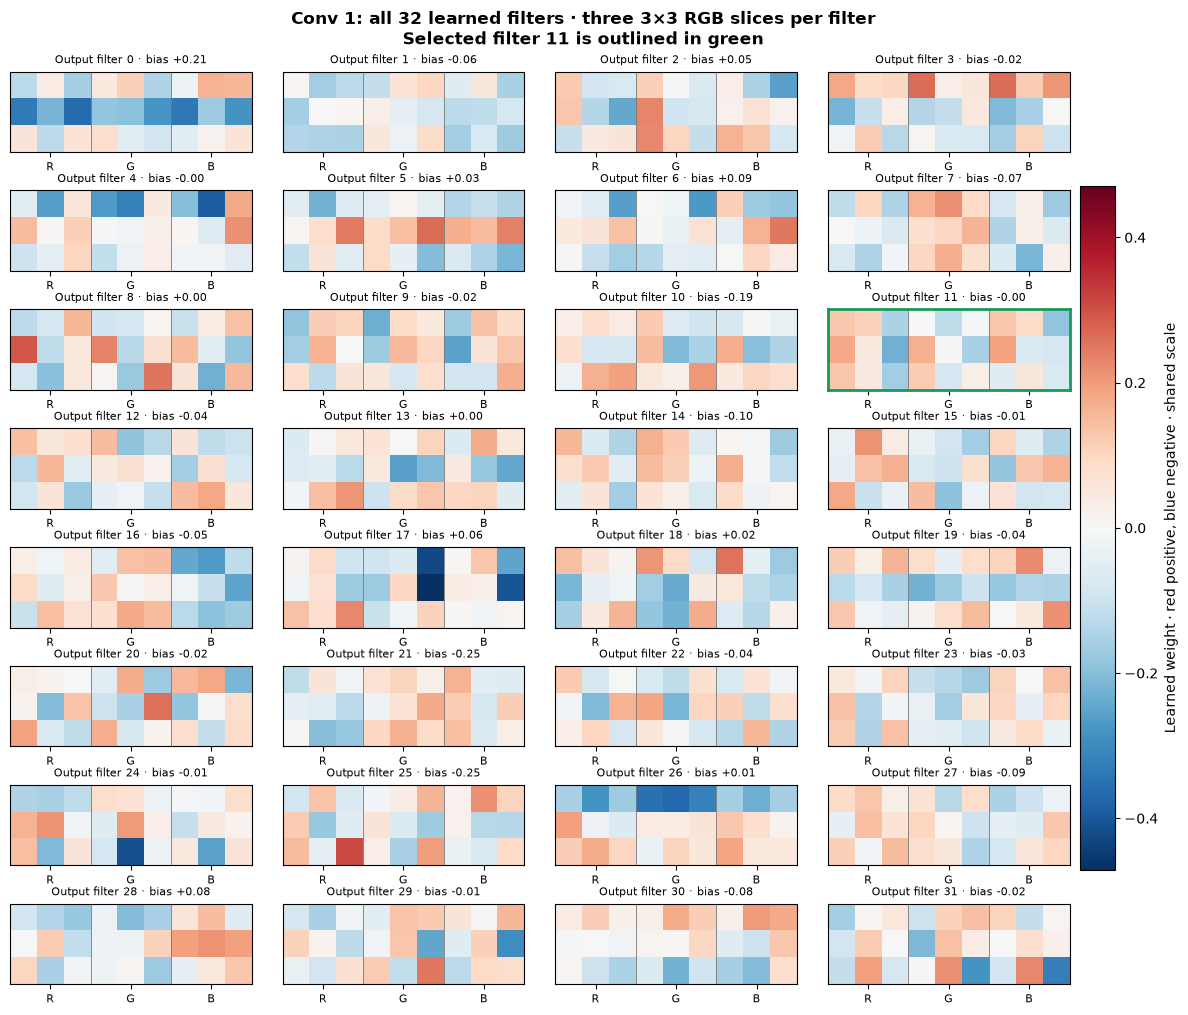

In [30]:
if internal_default_pair is not None:
    finish_internal_figure(
        internal_weight_figure(0, internal_default_channel), "conv1_weights"
    )


### 6.2 Follow the arithmetic of one convolution

To see what these numbers actually do, we will work through one response of the selected first-layer filter on the original resize example. We choose the position where this filter has its largest post-ReLU activation. The left column shows the 3×3 input values in each colour channel, scaled to 0–1; the middle column shows the learned weights at those positions; the right column shows their products. Summing all 27 products and adding the bias gives the convolution's response before ReLU. ReLU then keeps that value if it is positive, or returns zero otherwise. The calculation in the title is checked against the model's actual output at that position.

This is an exact calculation for one location, rather than an attribution approximation. It also explains why the weights and the activation are different things: the same weights slide across every location, but the input patch changes. In the explorer's second-layer calculation there are 32 incoming channels. It displays the three with the largest absolute product sums and explicitly includes the sum of the other 29 in the total.

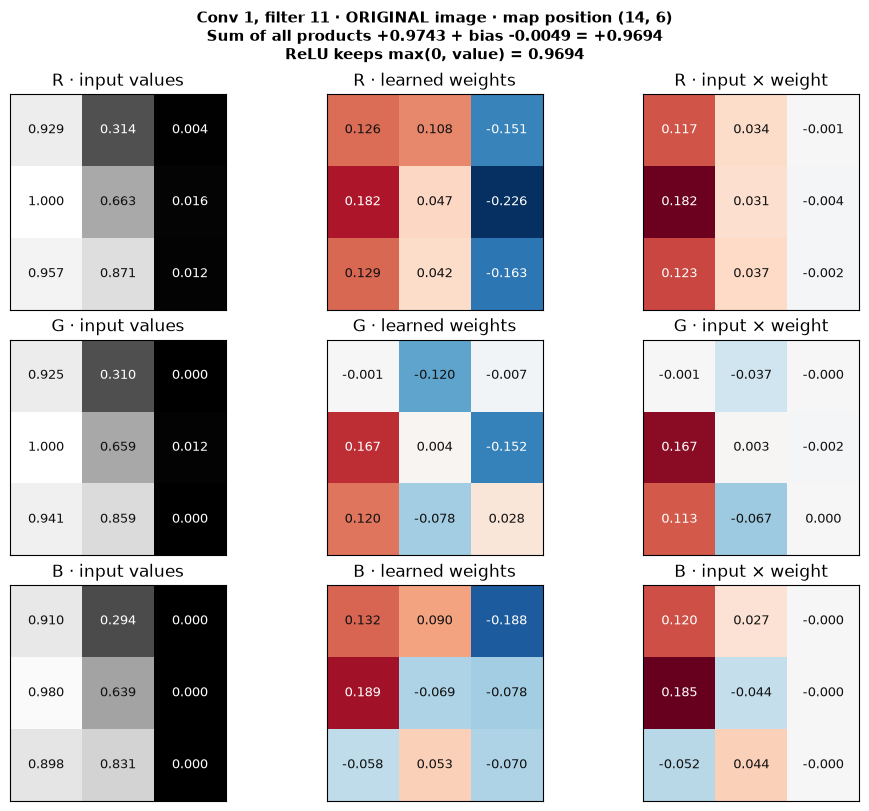

In [31]:
if internal_default_pair is not None:
    finish_internal_figure(
        internal_operation_figure(internal_default_pair, 0, internal_default_channel),
        "conv1_worked_calculation",
    )


### 6.3 How do the feature maps change after resizing?

We will now apply all 32 first-layer filters to the original image and its 32→28→32 version. Each panel shows one filter, with the original response on the left of the white divider and the modified response on the right. All panels share the same activation scale, so differences in brightness remain comparable across filters and versions. The numbers above each panel give its mean activation. These maps are taken after ReLU and before pooling, at their native 30×30 resolution; the second layer's corresponding maps are 13×13.

This lets us locate responses that disappear, weaken, or spread after an edit. It does not tell us by itself whether those changes help or hurt the classification: later layers combine the maps, and a bright response is not automatically evidence for either class. The next view connects a single channel to its input region and measures the change in prediction when that whole channel is zeroed.

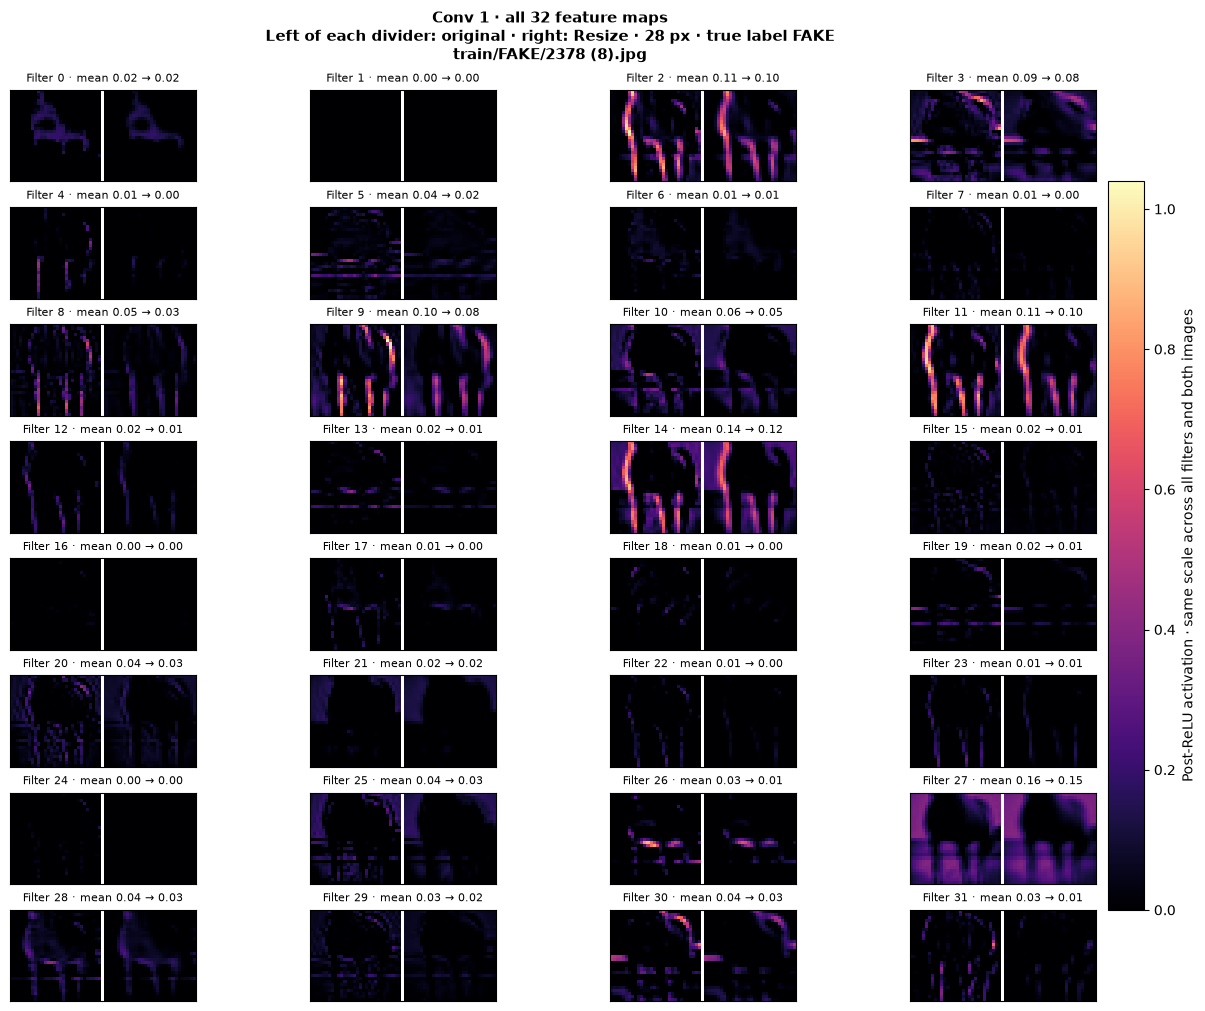

In [32]:
if internal_default_pair is not None:
    finish_internal_figure(
        internal_activation_figure(internal_default_pair, 0),
        "conv1_feature_maps_resize",
    )


Here we will follow only the selected filter through the same image pair. The middle column shows its response map, and the green square marks its strongest position. The green box on the original-sized input shows the input region that can affect that position; the right column enlarges that region. A first-layer response depends on a 3×3 input patch, while a second-layer response can depend on an 8×8 input region because the earlier convolution and pooling have already combined neighbouring pixels. These boxes are determined by the architecture, not by a saliency threshold.

The labels give the intact FAKE probability and the probability obtained after setting this entire channel to zero. That intervention affects all positions of the channel, not just the green box. A local peak and a channel's overall output effect therefore answer different questions. If a map is entirely zero, the view marks the absence of a positive response; a tied “peak” in such a map should not be read as a preferred region.

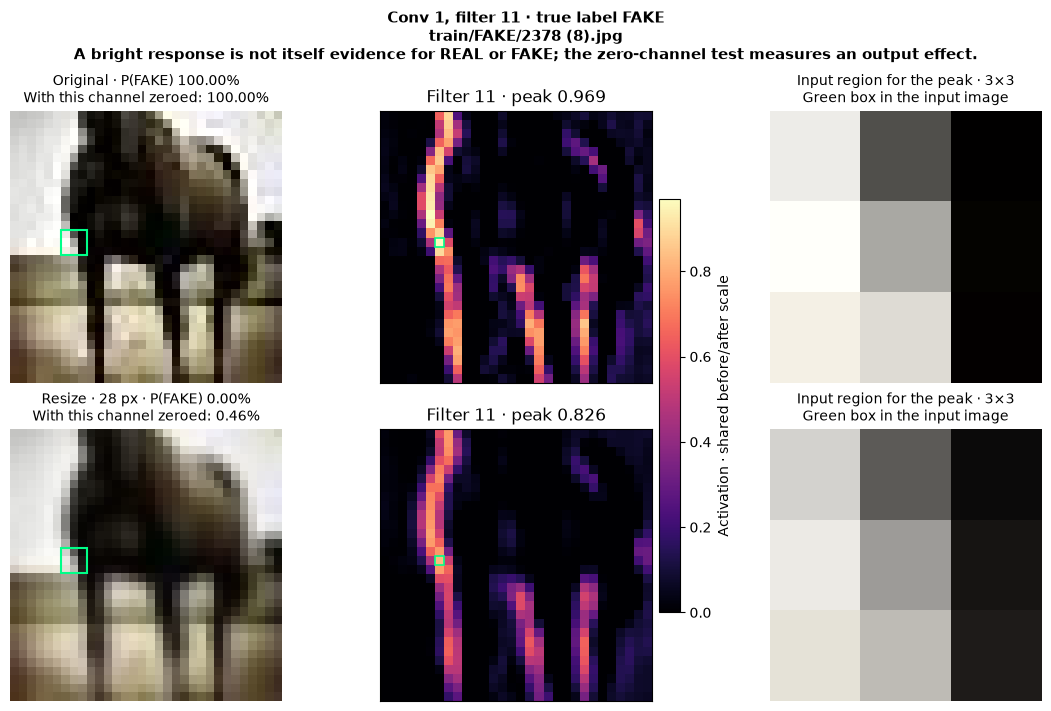

In [33]:
if internal_default_pair is not None:
    finish_internal_figure(
        internal_detail_figure(internal_default_pair, 0, internal_default_channel),
        "conv1_selected_filter_resize",
    )


### 6.4 What kinds of patches activate this filter?

The gallery below searches the original 2,000-image validation sample for the three images with the highest spatial activation of the selected filter. For each image, we will see the full image, its feature map, and the input patch corresponding to that peak. We select these examples by activation alone, without requiring a particular label or a correct prediction. This helps separate the pattern the filter responds to from the final classification that the rest of the network makes.

For the saved baseline's first-layer filter 11, the strongest patches show a bright region on the left transitioning to a dark region on the right. Together with its positive and negative weight pattern, this suggests sensitivity to that direction of contrast. The examples include both REAL and FAKE images, so it would be misleading to call it simply a “real-image detector.” Three examples also do not describe every pattern that can activate a filter; we will check the contrast interpretation using controlled inputs next.

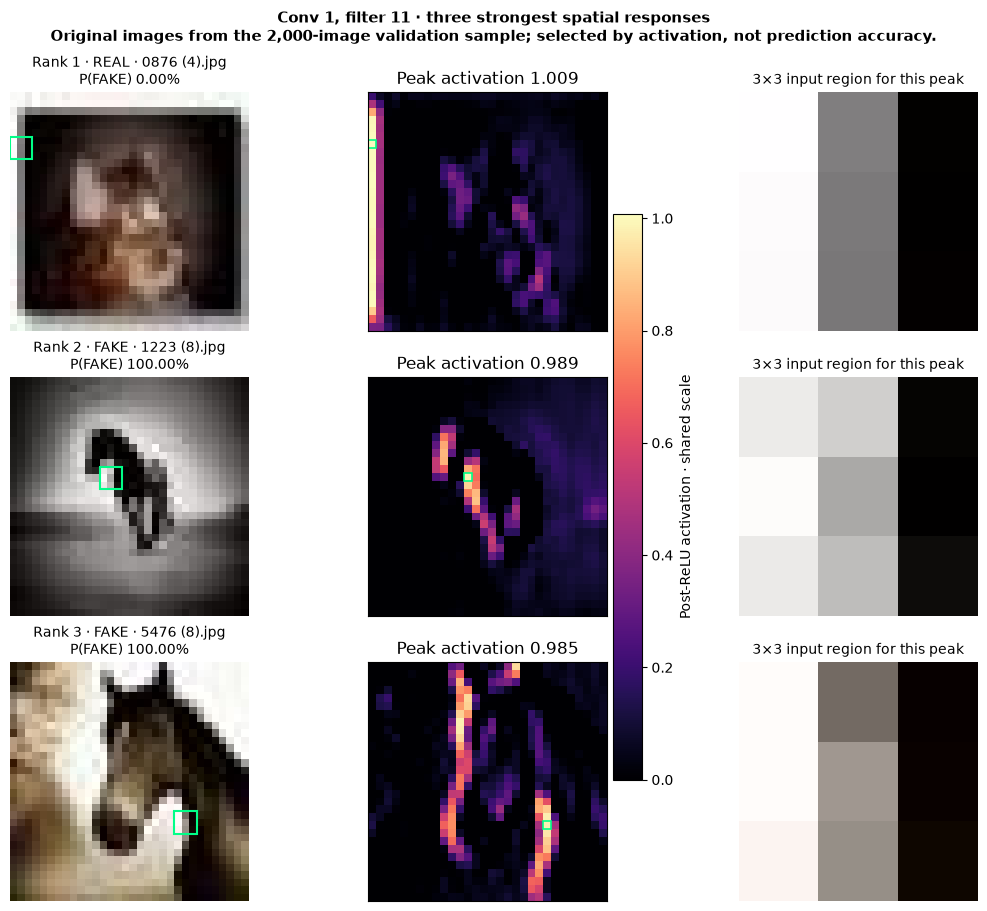

In [34]:
if internal_default_pair is not None:
    finish_internal_figure(
        internal_top_examples_figure(0, internal_default_channel),
        "conv1_strongest_examples",
    )


The next panel provides a small controlled check of that interpretation. We will feed the model flat black, grey and white images, vertical and horizontal brightness steps in both directions, and a one-pixel checkerboard. All three colour channels are identical, so these inputs isolate brightness patterns. The first row shows each input; the second row shows the selected filter's response, using one shared scale and reporting both the peak and mean activation. A large peak along a narrow edge can coexist with a small mean across the image.

These are synthetic diagnostic patterns, not CIFAKE examples or a new accuracy benchmark. They let us test whether a proposed direction of contrast really activates the filter, but cannot establish all of its colour preferences or its role in image classification. The explorer can apply this same fixed set of patterns to any channel in either convolutional layer.

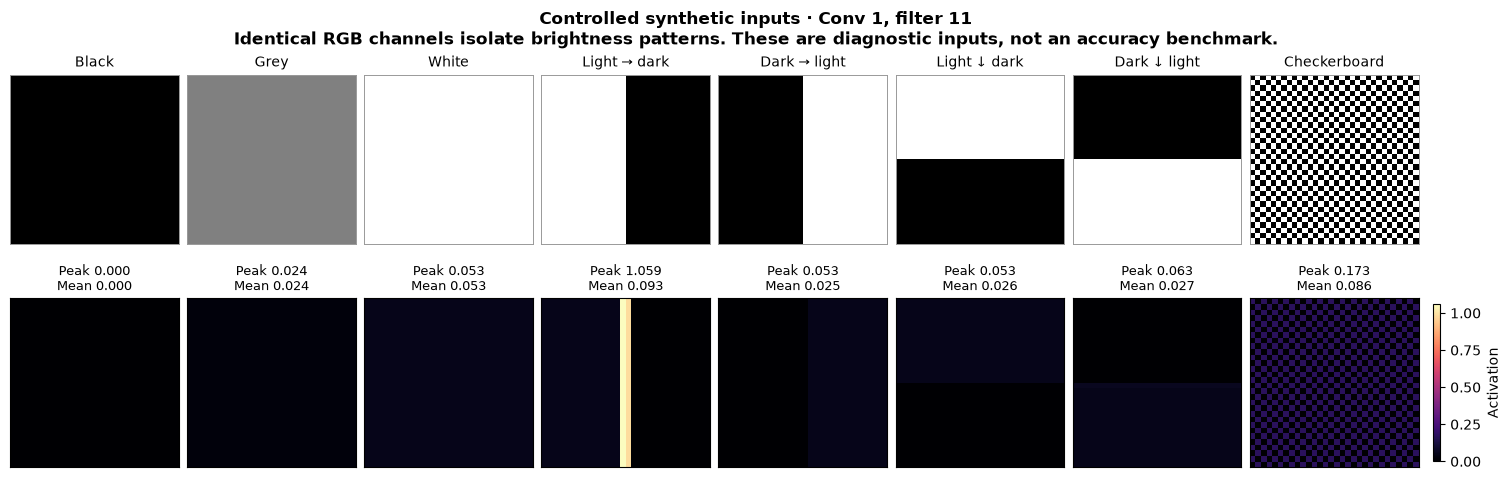

In [35]:
if internal_default_pair is not None:
    finish_internal_figure(
        internal_pattern_figure(0, internal_default_channel), "conv1_controlled_inputs"
    )


### 6.5 Which channels help, and under which conditions?

We will now compare performance with each channel switched off in turn. The channel is set to zero after its ReLU and before pooling, and the remaining network runs normally. Each point below is **intact accuracy minus accuracy after removal**, in percentage points, on the same balanced validation sample. Positive blue values mean removal causes a net loss of accuracy; negative orange values mean removal improves accuracy in that condition. Filters keep the same order across the three columns within each layer, making it easier to see when a channel's effect changes between clean, resized and JPEG images.

The thin lines are 95% pointwise paired-bootstrap intervals, resampling within each class while keeping intact and ablated predictions paired by image. They describe sampling variation for an individual comparison and are not adjusted for selecting among many filters. We will use them as exploratory context, not as a significance ranking. A zero effect on this sample does not prove that a channel is useless; other channels may compensate, and the response can depend on the image distribution. Zeroing a channel also creates an artificial internal state, so this is not the same experiment as retraining a model without that filter.

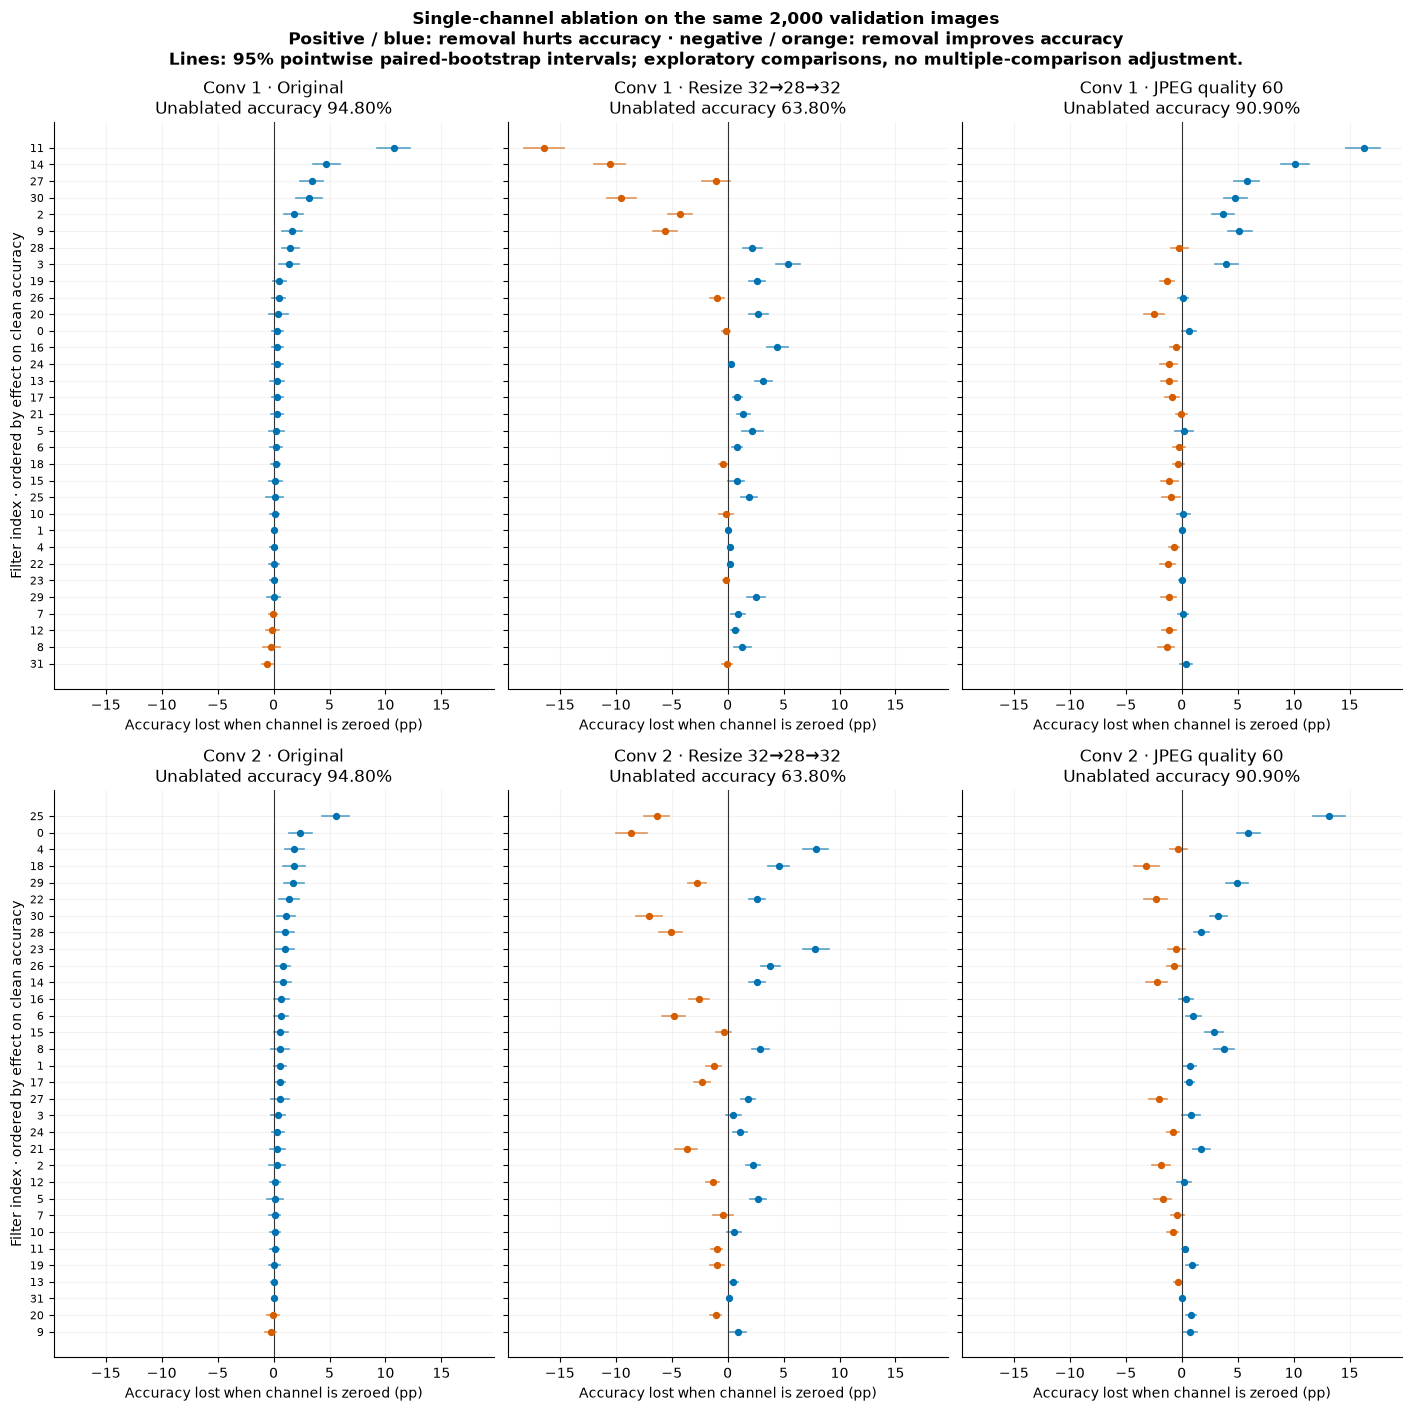

**Conv 1, filter 11: paired error changes**

| Condition | Accuracy: intact | Accuracy: zeroed | Accuracy lost (pp) | New mistakes | Mistakes repaired | Fake detected: intact → zeroed | Real false alarms: intact → zeroed |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Original | 94.80% | 84.05% | +10.75 | 265 | 50 | 94.9% → 99.9% | 5.3% → 31.8% |
| Resize 32→28→32 | 63.80% | 80.25% | -16.45 | 80 | 409 | 27.8% → 68.7% | 0.2% → 8.2% |
| JPEG quality 60 | 90.90% | 74.65% | +16.25 | 336 | 11 | 98.9% → 100.0% | 17.1% → 50.7% |

**Conv 2, filter 25: paired error changes**

| Condition | Accuracy: intact | Accuracy: zeroed | Accuracy lost (pp) | New mistakes | Mistakes repaired | Fake detected: intact → zeroed | Real false alarms: intact → zeroed |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Original | 94.80% | 89.25% | +5.55 | 144 | 33 | 94.9% → 98.2% | 5.3% → 19.7% |
| Resize 32→28→32 | 63.80% | 70.10% | -6.30 | 10 | 136 | 27.8% → 41.3% | 0.2% → 1.1% |
| JPEG quality 60 | 90.90% | 77.75% | +13.15 | 271 | 8 | 98.9% → 99.7% | 17.1% → 44.2% |

In [36]:
# Read the saved interventions to see which channel removals harm or repair predictions.
if internal_default_pair is not None:
    finish_internal_figure(internal_ablation_figure(), "channel_ablation_validation")
    for li, ch in [(0, internal_default_channel), (1, internal_second_channel)]:
        display(
            Markdown(
                f"**{INTERNAL_LAYERS[li]['name']}, filter {ch}: paired error changes**"
            )
        )
        show_table(INTERNAL_TABLE_HEADERS, internal_channel_rows(li, ch))


### 6.6 Inspect another filter or image

Choose a layer, filter index, preview image, modification and strength, then press **Inspect filter**. The tabs link the selected response maps to the weights, a worked convolution on the original preview, the strongest dataset examples, all feature maps, controlled test patterns, and aggregate ablation results. The first-layer weight tab shows all 32 filters with the selected one outlined; the second-layer weight tab shows the 32 input-channel slices of the selected output filter. Strength zero compares an image with itself.

The selected response and all-map tabs follow the image controls. The strongest examples and synthetic patterns follow the filter choice, while the ablation table always reports the three fixed conditions on the 2,000-image sample. Keeping that distinction visible prevents a preview of one image from being confused with a population result. The controls need a live kernel, but use the model and images already included in this notebook; GitHub can display the saved static figures above.

In [37]:
if internal_default_pair is not None:
    import html
    import ipywidgets as widgets

    internal_image_choice = widgets.Dropdown(
        options=[
            (
                f"{'FAKE' if behavior_labels[int(i)]==0 else 'REAL'} · {behavior_arrays['paths'][int(i)]}",
                int(i),
            )
            for i in behavior_arrays["preview_indices"]
        ],
        value=internal_default_pair["index"],
        description="Image:",
        layout=widgets.Layout(width="95%"),
    )
    internal_layer_choice = widgets.Dropdown(
        options=[("Conv 1", 0), ("Conv 2", 1)], value=0, description="Layer:"
    )
    internal_filter_choice = widgets.IntSlider(
        value=internal_default_channel,
        min=0,
        max=31,
        description="Filter:",
        continuous_update=False,
    )
    internal_family_choice = widgets.Dropdown(
        options=list(PROBE_FAMILIES), value="Resize", description="Change:"
    )
    internal_level_choice = widgets.IntSlider(
        value=1, min=0, max=4, description="Strength:", continuous_update=False
    )
    internal_button = widgets.Button(
        description="Inspect filter", icon="search", button_style="primary"
    )
    internal_status = widgets.HTML()
    internal_details = widgets.HTML()
    internal_table = widgets.HTML()
    internal_plot_widgets = [
        widgets.Image(format="png", layout=widgets.Layout(width="100%"))
        for _ in range(6)
    ]
    internal_tabs = widgets.Tab(children=[*internal_plot_widgets, internal_table])
    for i, title in enumerate(
        [
            "Responses",
            "Weights",
            "Calculation",
            "Examples",
            "All maps",
            "Test patterns",
            "Ablation",
        ]
    ):
        internal_tabs.set_title(i, title)
    internal_explorer_state = {}

    def mark_internal_stale(change=None):
        internal_status.value = "<b>Settings changed.</b> The results still show the previous selection. Press Inspect filter to update."

    def update_internal_explorer(button=None):
        internal_button.disabled = True
        internal_status.value = "Computing and rendering filter views…"
        try:
            if behavior_model_digest(model) != internal_report["model_state_sha256"]:
                raise ValueError(
                    "The model changed; reload a matching internal probe before using the explorer"
                )
            index = int(internal_image_choice.value)
            li, ch = int(internal_layer_choice.value), int(internal_filter_choice.value)
            family, level = internal_family_choice.value, int(
                internal_level_choice.value
            )
            pair = get_internal_pair(index, family, level)
            draws = [
                lambda: internal_detail_figure(pair, li, ch),
                lambda: internal_weight_figure(li, ch),
                lambda: internal_operation_figure(pair, li, ch),
                lambda: internal_top_examples_figure(li, ch),
                lambda: internal_activation_figure(pair, li),
                lambda: internal_pattern_figure(li, ch),
            ]
            pngs = []
            for draw in draws:
                fig = draw()
                try:
                    stream = BytesIO()
                    fig.savefig(
                        stream,
                        format="png",
                        dpi=110,
                        bbox_inches="tight",
                        facecolor="white",
                    )
                    pngs.append(stream.getvalue())
                finally:
                    plt.close(fig)
            for target, png in zip(internal_plot_widgets, pngs):
                target.value = png
            header = "".join(
                f'<th style="padding:6px">{html.escape(h)}</th>'
                for h in INTERNAL_TABLE_HEADERS
            )
            body = "".join(
                "<tr>"
                + "".join(
                    f'<td style="padding:6px">{html.escape(str(value))}</td>'
                    for value in row
                )
                + "</tr>"
                for row in internal_channel_rows(li, ch)
            )
            internal_table.value = (
                f'<p><b>{INTERNAL_LAYERS[li]["name"]}, filter {ch}</b> · '
                f'{internal_report["n"]:,} validation images. These three cohort conditions stay fixed when the preview controls change.</p>'
                f'<div style="overflow-x:auto"><table><tr>{header}</tr>{body}</table></div>'
                "<p>Positive accuracy lost means removal hurts; negative means removal helps. "
                "New mistakes and repaired mistakes are paired image counts, relative to the intact model under that condition.</p>"
            )
            p = internal_pfake(pair["logits_real"])
            removed = internal_pfake(pair["ablated_logits_real"][li, ch])
            means = pair["maps"][li][:, ch].mean((1, 2))
            internal_details.value = (
                f'<b>Showing {INTERNAL_LAYERS[li]["name"]}, filter {ch}</b> · true label {pair["truth"]} · '
                f'<code>{html.escape(pair["path"])}</code><br>'
                f'Original → {html.escape(pair["setting"])} · mean activation {means[0]:.3f} → {means[1]:.3f}<br>'
                f"Intact P(FAKE): {p[0]:.2%} → {p[1]:.2%}; with this channel zeroed: {removed[0]:.2%} → {removed[1]:.2%}.<br>"
                "The worked convolution uses the original preview. Strongest examples come from the fixed validation sample."
            )
            internal_explorer_state.update(
                index=index, layer=li, channel=ch, family=family, level=level, pair=pair
            )
            internal_status.value = (
                "<b>Ready.</b> All tabs match the filter and image recorded below."
            )
        except Exception as error:
            internal_status.value = f"<b>Could not update.</b> {html.escape(str(error))}. Existing results still show the previous selection."
            raise
        finally:
            internal_button.disabled = False

    for control in [
        internal_image_choice,
        internal_layer_choice,
        internal_filter_choice,
        internal_family_choice,
        internal_level_choice,
    ]:
        control.observe(mark_internal_stale, names="value")
    internal_button.on_click(update_internal_explorer)
    update_internal_explorer()
    display(
        widgets.VBox(
            [
                internal_image_choice,
                widgets.HBox([internal_layer_choice, internal_filter_choice]),
                widgets.HBox(
                    [internal_family_choice, internal_level_choice, internal_button]
                ),
                internal_status,
                internal_details,
                internal_tabs,
            ]
        )
    )
    print(
        "Run this cell with a live kernel to inspect filters. Static examples and all-channel ablation results are saved above."
    )


Run this cell with a live kernel to inspect filters. Static examples and all-channel ablation results are saved above.


### 6.7 What this investigation tells us

For the saved baseline, first-layer filter 11 has the largest clean-accuracy loss under single-channel removal. Its weights, strongest image patches and controlled-input responses support a description of sensitivity to a bright-to-dark transition from left to right. That is a local pattern description, not a semantic class label. Its activation on both real and fake examples shows why we need to follow the signal through the rest of the network.

The same channel has a distribution-dependent effect. Removing it changes clean sample accuracy from **94.80% to 84.05%**, but changes resized-image accuracy from **63.80% to 80.25%**. On resized images, fake detection rises from **27.8% to 68.7%**, while real-image false alarms also rise from **0.2% to 8.2%**. The higher accuracy is therefore a trade-off, not an across-the-board improvement. On JPEG images, removal lowers accuracy from **90.90% to 74.65%**. Second-layer filter 25 shows a similar sign change between clean and resized conditions. These numbers describe the saved model and this selected validation sample; the tables above recalculate for another compatible run.

The explanation is now more concrete than “resizing changes the score”: we can show learned spatial weights, verify their arithmetic, locate their responses, and measure how removing a channel changes errors. These results still do not establish a complete explanation of the clean-to-resized failure, or a justified pruning rule. In the illustrated fake-image pair, removing filter 11 alone does not reverse the resized image's incorrect REAL prediction. Several channels and the later layers act together, so the next hypothesis should be tested with controlled comparisons rather than naming a single filter as the cause of every failure.

**Calculation checks:** feature maps are compared with hooks on the model's normal forward pass; channel removal is compared with an independent forward-hook intervention; the displayed products plus bias reconstruct the convolution response; example rankings, input-region coordinates, zero-effect cases and the interactive controls are checked. The model weights and saved test evaluation remain fixed throughout this analysis.

## 7. What the internal views show so far

The explanation views connect those changes to the computation. Grad-CAM highlights coarse regions supporting the FAKE score; occlusion asks how the score changes when a small patch is covered; and the final-layer chart reconstructs the REAL logit from **64 activation-times-weight contributions plus the bias**. Looking at learned filters, their response maps and their most activating patches helps us describe local patterns. These views complement one another: a bright heatmap region or a large weight alone is not a complete explanation of a decision.

The strongest concrete internal finding concerns **first-layer channel 11**. On the fixed 2,000-image validation cohort, zeroing it reduced clean accuracy from **94.80% to 84.05%**, but increased resized-image accuracy from **63.80% to 80.25%**. That improvement involved a trade-off: fake detection rose from **27.8% to 68.7%**, while real images incorrectly flagged as fake rose from **0.2% to 8.2%**. JPEG-quality-60 accuracy also fell from **90.90% to 74.65%**. The filter weights, activation examples and synthetic pattern checks are consistent with sensitivity to a local bright-to-dark transition. Removing it does not reverse every illustrated error, so it is not a single explanation for all resizing failures. The intervention shows a measurable dependence on one channel under specific conditions; it does not justify deleting that channel as a general fix.


**Questions carried over from Phase I** (`phase1/04_what_fools_the_detectors.ipynb`):

- **Where does the sharpness dial live?** Blur, resizing, JPEG and sharpening all move the output along one fine-detail axis. Filter 11's bright-to-dark sensitivity and its clean-versus-resize trade-off make the first layer a natural place to start: do early responses track the Laplacian sharpness score?
- **Why does noise behave differently?** Noise adds fine detail like sharpening, yet it makes fakes look *less* fake. Comparing feature maps for sharpened and noisy versions of the same fake would show where the two kinds of detail separate.
- **Is there a colour pathway?** Saturated fakes start further on the FAKE side for the CNN (not for ResNet18), and desaturating blurred fakes removes much of their remaining detection. Channel removal on the saturated frog and deer images could show which channels carry that.